## PART 2 — DATA CO SUPPLY CHAIN
Business question: What factors are related to late delivery, and how can the data be prepared for the prediction models in Parts 3–5?

This part covers data understanding, missing values, duplicates, target analysis, EDA, outliers, correlation, time analysis and preprocessing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv("DataCoSupplyChainDataset (1).csv", encoding="latin1")
df.head()


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


## Interpretation: The dataset contains order and customer information along with delivery-related variables. The target variable for the project is Late_delivery_risk.

In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

Rows: 180519
Columns: 53
<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname  

In [10]:
df.describe()


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Price,Product Status
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,...,180519.000000,180519.000000,180519.000000,180519.000000,24840.000000,180519.000000,180519.000000,0.0,180519.000000,180519.0
mean,3.497654,2.931847,21.974989,183.107609,0.548291,31.851451,6691.379495,35921.126914,5.443460,29.719955,...,2.127638,203.772096,183.107609,21.974989,55426.132327,692.509764,31.851451,NaN,141.232550,0.0
std,1.623722,1.374449,104.433526,120.043670,0.497664,15.640064,4162.918106,37542.461122,1.629246,9.813646,...,1.453451,132.273077,120.043670,104.433526,31919.279101,336.446807,15.640064,NaN,139.732492,0.0
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,2.000000,1.000000,603.000000,2.000000,-33.937553,...,1.000000,9.990000,7.490000,-4274.979980,1040.000000,19.000000,2.000000,NaN,9.990000,0.0
25%,2.000000,2.000000,7.000000,104.379997,0.000000,18.000000,3258.500000,725.000000,4.000000,18.265432,...,1.000000,119.980003,104.379997,7.000000,23464.000000,403.000000,18.000000,NaN,50.000000,0.0
50%,3.000000,4.000000,31.520000,163.990005,1.000000,29.000000,6457.000000,19380.000000,5.000000,33.144863,...,1.000000,199.919998,163.990005,31.520000,59405.000000,627.000000,29.000000,NaN,59.990002,0.0
75%,5.000000,4.000000,64.800003,247.399994,1.000000,45.000000,9779.000000,78207.000000,7.000000,39.279617,...,3.000000,299.950012,247.399994,64.800003,90008.000000,1004.000000,45.000000,NaN,199.990005,0.0
max,6.000000,4.000000,911.799988,1939.989990,1.000000,76.000000,20757.000000,99205.000000,12.000000,48.781933,...,5.000000,1999.989990,1939.989990,911.799988,99301.000000,1363.000000,76.000000,NaN,1999.989990,0.0


## Interpretation: The dataset has 180,519 rows and 53 columns. It contains both numerical and categorical variables. This means some categorical columns will need to be converted into numbers before machine learning.

In [14]:
df.dtypes

Type                                 str
Days for shipping (real)           int64
Days for shipment (scheduled)      int64
Benefit per order                float64
Sales per customer               float64
Delivery Status                      str
Late_delivery_risk                 int64
Category Id                        int64
Category Name                        str
Customer City                        str
Customer Country                     str
Customer Email                       str
Customer Fname                       str
Customer Id                        int64
Customer Lname                       str
Customer Password                    str
Customer Segment                     str
Customer State                       str
Customer Street                      str
Customer Zipcode                 float64
Department Id                      int64
Department Name                      str
Latitude                         float64
Longitude                        float64
Market          

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

In [8]:
df.describe(include="object")

C:\Users\Anshika Pandey\AppData\Local\Temp\ipykernel_12064\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Type,Delivery Status,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Lname,Customer Password,Customer Segment,...,Order City,Order Country,order date (DateOrders),Order Region,Order State,Order Status,Product Image,Product Name,shipping date (DateOrders),Shipping Mode
count,180519,180519,180519,180519,180519,180519,180519,180511,180519,180519,...,180519,180519,180519,180519,180519,180519,180519,180519,180519,180519
unique,4,4,50,563,2,1,782,1109,1,3,...,3597,164,65752,23,1089,9,118,118,63701,4
top,DEBIT,Late delivery,Cleats,Caguas,EE. UU.,XXXXXXXXX,Mary,Smith,XXXXXXXXX,Consumer,...,Santo Domingo,Estados Unidos,10/25/2016 14:39,Central America,Inglaterra,COMPLETE,http://images.acmesports.sports/Perfect+Fitnes...,Perfect Fitness Perfect Rip Deck,5/9/2015 18:02,Standard Class
freq,69295,98977,24551,66770,111146,180519,65150,64104,180519,93504,...,2211,24840,5,28341,6722,59491,24515,24515,10,107752


## Missing Value

In [7]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print(missing)


Product Description    180519
Order Zipcode          155679
Customer Lname              8
Customer Zipcode            3
dtype: int64


In [11]:
missing_percent = (df.isnull().sum() / len(df) * 100)
missing_percent = missing_percent[missing_percent > 0].sort_values(ascending=False)

print(missing_percent)


Product Description    100.000000
Order Zipcode           86.239676
Customer Lname           0.004432
Customer Zipcode         0.001662
dtype: float64


## Interpretation: Product Description has 100% missing values and Order Zipcode has a very high percentage of missing values. A few values are also missing in customer name/zipcode fields. These columns need to be handled before modelling.

In [12]:
missing_table = pd.DataFrame()
missing_table["Missing Values"] = df.isnull().sum()
missing_table["Missing Percentage"] = df.isnull().sum() / len(df) * 100
missing_table = missing_table[missing_table["Missing Values"] > 0]
missing_table.sort_values("Missing Percentage", ascending=False)

,Missing Values,Missing Percentage
Product Description,180519,100.000000
Order Zipcode,155679,86.239676
Customer Lname,8,0.004432
Customer Zipcode,3,0.001662


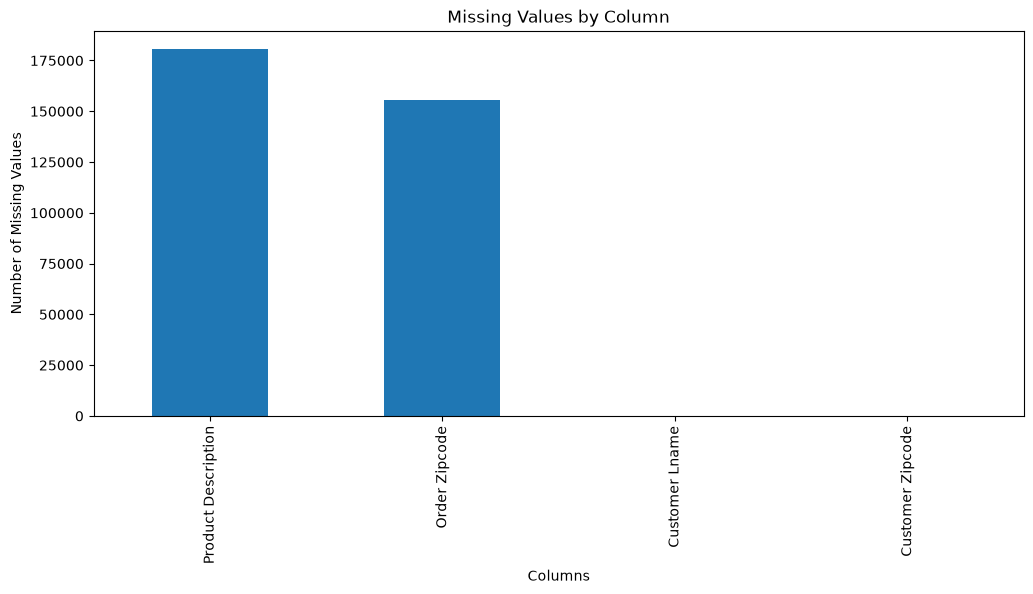

In [13]:
missing_table["Missing Values"].sort_values(ascending=False).plot(kind="bar", figsize=(12,5))
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.title("Missing Values by Column")
plt.xticks(rotation=90)
plt.show()

## Duplicate values

In [14]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


## Interpretation: There are no duplicate rows, so no duplicate records need to be removed.

## Target variable

In [15]:
print(df["Late_delivery_risk"].value_counts())
print()
print((df["Late_delivery_risk"].value_counts(normalize=True) * 100).round(2))



Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Late_delivery_risk
1    54.83
0    45.17
Name: proportion, dtype: float64


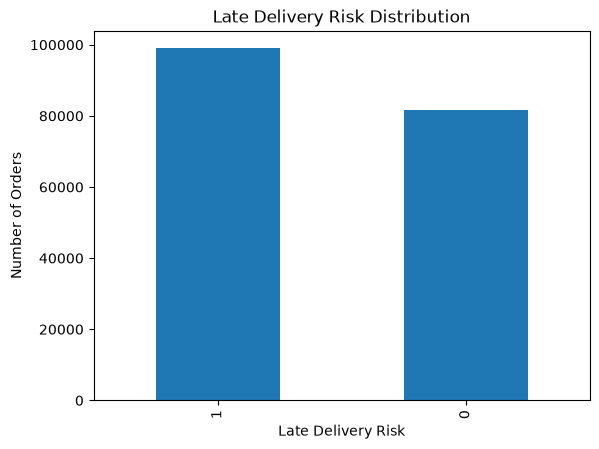

In [16]:
df["Late_delivery_risk"].value_counts().plot(kind="bar")

plt.xlabel("Late Delivery Risk")
plt.ylabel("Number of Orders")
plt.title("Late Delivery Risk Distribution")
plt.show()


## Interpretation: Around 54.83% of orders are classified as late-risk and 45.17% are not. The classes are reasonably balanced, so accuracy alone should not be used later; precision, recall, F1-score and AUC should also be checked.

## Shiping Mode

In [18]:
df["Shipping Mode"].value_counts()

Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737
Name: count, dtype: int64

In [19]:
shipping_late = pd.crosstab(df["Shipping Mode"], df["Late_delivery_risk"], normalize="index") * 100
shipping_late

Late_delivery_risk,0,1
Shipping Mode,,
First Class,4.677501,95.322499
Same Day,54.256958,45.743042
Second Class,23.367219,76.632781
Standard Class,61.928317,38.071683


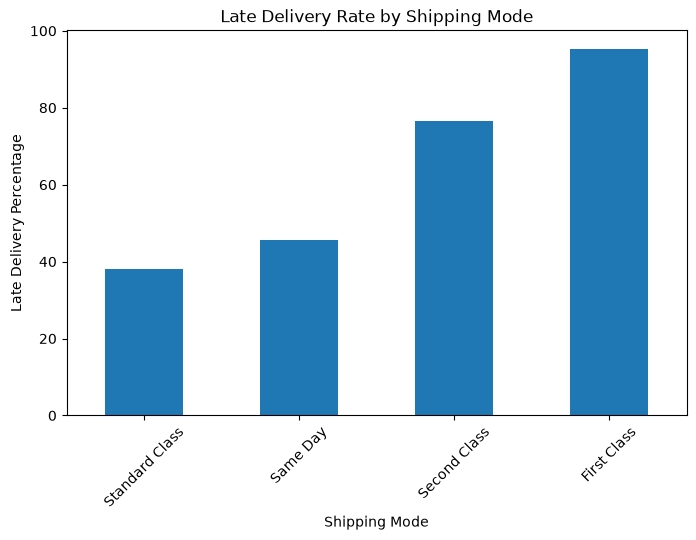

In [20]:
shipping_late[1].sort_values().plot(kind="bar", figsize=(8,5))
plt.xlabel("Shipping Mode")
plt.ylabel("Late Delivery Percentage")
plt.title("Late Delivery Rate by Shipping Mode")
plt.xticks(rotation=45)
plt.show()

## Interpretation: Shipping mode shows a strong difference in late delivery. First Class has about 95.32% late-risk, while Standard Class has about 38.07%. This makes shipping mode an important variable for the later prediction model.

## Customer segment

In [26]:
df["Customer Segment"].value_counts()
segment_late = pd.crosstab(df["Customer Segment"], df["Late_delivery_risk"], normalize="index") * 100
segment_late

Late_delivery_risk,0,1
Customer Segment,,
Consumer,45.191650,54.808350
Corporate,45.277337,54.722663
Home Office,44.929560,55.070440


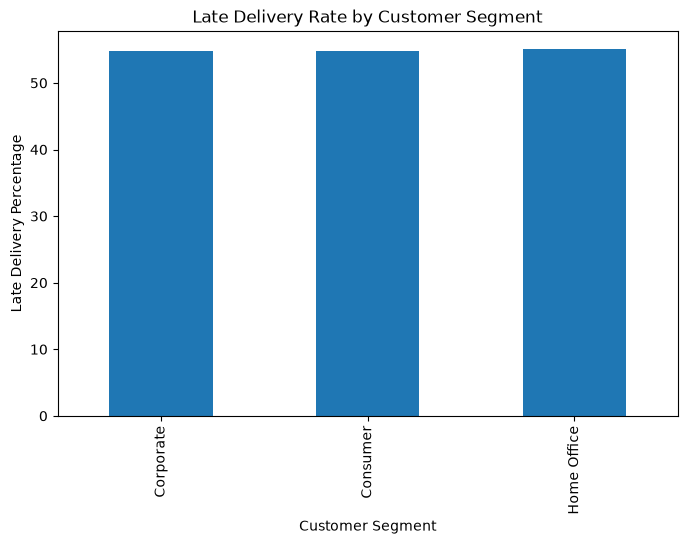

In [27]:
segment_late[1].sort_values().plot(kind="bar", figsize=(8,5))
plt.xlabel("Customer Segment")
plt.ylabel("Late Delivery Percentage")
plt.title("Late Delivery Rate by Customer Segment")
plt.show()

## Interpretation: The three customer segments have very similar late-delivery rates, around 55%. Therefore, customer segment appears to have a smaller difference than shipping mode.

## Market


In [28]:
df["Market"].value_counts()

Market
LATAM           51594
Europe          50252
Pacific Asia    41260
USCA            25799
Africa          11614
Name: count, dtype: int64

In [29]:
market_late = pd.crosstab(df["Market"], df["Late_delivery_risk"], normalize="index") * 100
market_late

Late_delivery_risk,0,1
Market,,
Africa,45.410711,54.589289
Europe,44.792247,55.207753
LATAM,45.644842,54.355158
Pacific Asia,44.953951,55.046049
USCA,45.199426,54.800574


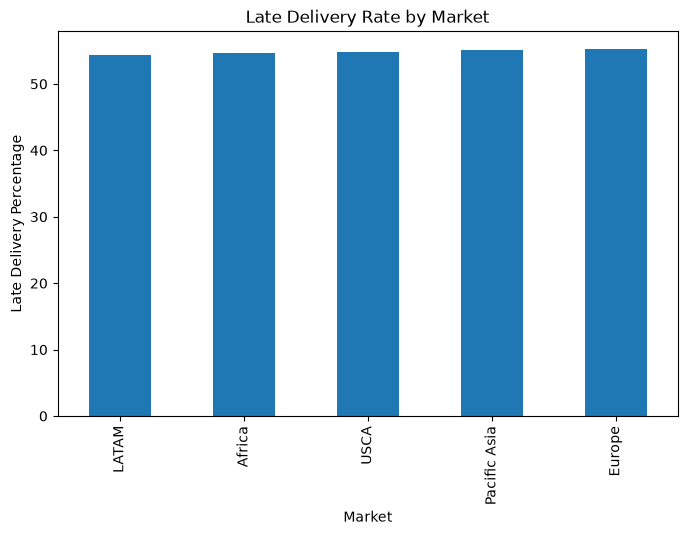

In [30]:
market_late[1].sort_values().plot(kind="bar", figsize=(8,5))
plt.xlabel("Market")
plt.ylabel("Late Delivery Percentage")
plt.title("Late Delivery Rate by Market")
plt.show()

## Interpretation: Late delivery rates are fairly similar across markets. Europe is slightly higher at about 55.21%, while LATAM is slightly lower at about 54.36%. Market may provide some information, but the difference is not very large.

## Sales

In [31]:
df["Sales"].describe()


count    180519.000000
mean        203.772096
std         132.273077
min           9.990000
25%         119.980003
50%         199.919998
75%         299.950012
max        1999.989990
Name: Sales, dtype: float64

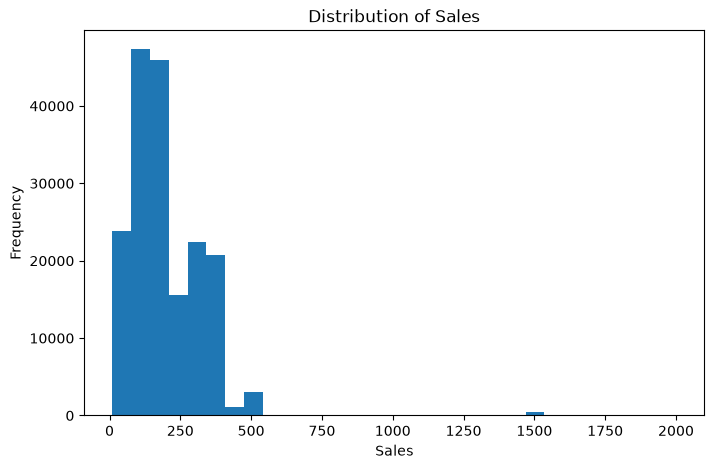

In [32]:
df["Sales"].plot(kind="hist", bins=30, figsize=(8,5))
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.title("Distribution of Sales")
plt.show()

## Interpretation: Sales values vary widely. Most orders are concentrated at lower and medium sales values, while a few orders have much higher sales.

## Average sales by late delivery 

In [33]:
df.groupby("Late_delivery_risk")["Sales"].mean()

Late_delivery_risk
0    204.291528
1    203.344163
Name: Sales, dtype: float64

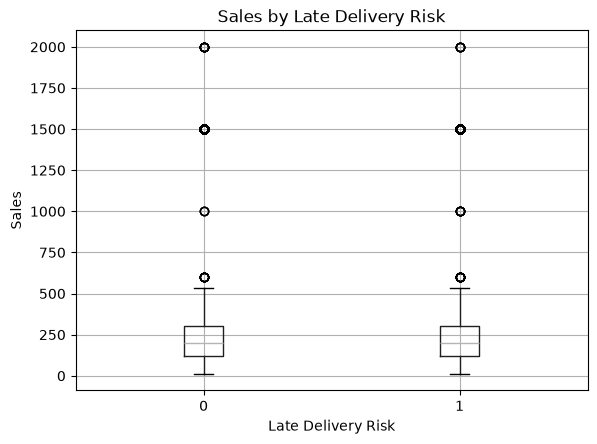

In [34]:
df.boxplot(column="Sales", by="Late_delivery_risk")
plt.xlabel("Late Delivery Risk")
plt.ylabel("Sales")
plt.title("Sales by Late Delivery Risk")
plt.suptitle("")
plt.show()

In [35]:
df["Order Item Quantity"].describe()
df["Order Item Quantity"].value_counts().sort_index()

Order Item Quantity
1    99134
2    20315
3    20350
4    20335
5    20385
Name: count, dtype: int64

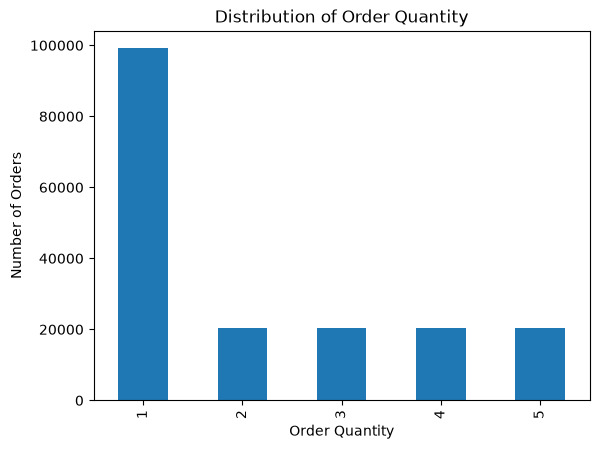

In [36]:
df["Order Item Quantity"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Order Quantity")
plt.ylabel("Number of Orders")
plt.title("Distribution of Order Quantity")
plt.show()

## Interpretation: Average sales are almost the same for both groups: about 204.29 for non-late-risk orders and 203.34 for late-risk orders. So sales alone does not show a strong difference in late delivery.

## Shipping mode vs late delivery

In [21]:
pd.crosstab(df["Shipping Mode"], df["Late_delivery_risk"])

Late_delivery_risk,0,1
Shipping Mode,,
First Class,1301,26513
Same Day,5283,4454
Second Class,8229,26987
Standard Class,66729,41023


In [38]:
pd.crosstab(df["Shipping Mode"], df["Late_delivery_risk"], normalize="index") * 100

Late_delivery_risk,0,1
Shipping Mode,,
First Class,4.677501,95.322499
Same Day,54.256958,45.743042
Second Class,23.367219,76.632781
Standard Class,61.928317,38.071683


## Interpretation: Most orders contain one item. Smaller numbers of orders contain 2–5 items. This variable can still be useful for the prediction model.

## Customer Segment vs Late Delivery


In [39]:
pd.crosstab(df["Customer Segment"], df["Late_delivery_risk"])

Late_delivery_risk,0,1
Customer Segment,,
Consumer,42256,51248
Corporate,24807,29982
Home Office,14479,17747


In [40]:
pd.crosstab(df["Customer Segment"], df["Late_delivery_risk"], normalize="index") * 100

Late_delivery_risk,0,1
Customer Segment,,
Consumer,45.191650,54.808350
Corporate,45.277337,54.722663
Home Office,44.929560,55.070440


## Interpretation: Consumer, Corporate and Home Office customers have almost the same late-risk percentage. Customer segment is therefore less important than shipping mode at the basic EDA level.

## Market vs Late Delivery

In [41]:
pd.crosstab(df["Market"], df["Late_delivery_risk"])


Late_delivery_risk,0,1
Market,,
Africa,5274,6340
Europe,22509,27743
LATAM,23550,28044
Pacific Asia,18548,22712
USCA,11661,14138


In [42]:
pd.crosstab(df["Market"], df["Late_delivery_risk"], normalize="index") * 100

Late_delivery_risk,0,1
Market,,
Africa,45.410711,54.589289
Europe,44.792247,55.207753
LATAM,45.644842,54.355158
Pacific Asia,44.953951,55.046049
USCA,45.199426,54.800574


In [43]:
# Sales Vs Late delivery 
df.groupby("Late_delivery_risk")["Sales"].mean()

Late_delivery_risk
0    204.291528
1    203.344163
Name: Sales, dtype: float64

## Interpretation: The difference between markets is small. However, market can still be included as a possible predictor and its importance can be checked by the models later.

## Outlier Analysis

In [46]:
Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
outliers = df[(df["Sales"] < lower_limit) | (df["Sales"] > upper_limit)]
print("Number of Sales outliers:", len(outliers))
print("Outlier Percentage:", len(outliers) / len(df) * 100)

Number of Sales outliers: 488
Outlier Percentage: 0.27033165483965677


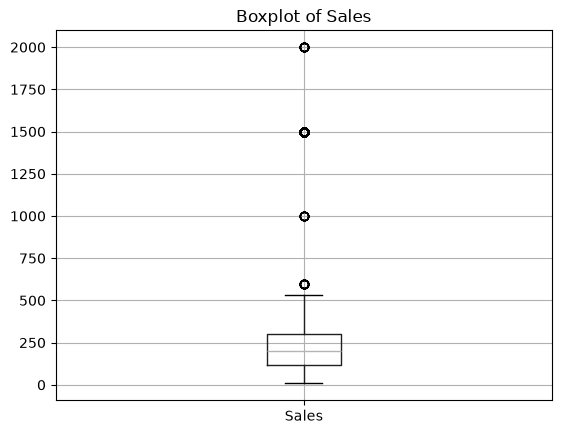

In [47]:
df.boxplot(column="Sales")
plt.title("Boxplot of Sales")
plt.show()

## Interpretation: There are 488 sales outliers, which is only about 0.27% of the dataset. The number is small, so the outliers are not removed because they may represent genuine high-value orders.

## Correlation Analysis

In [23]:
numerical_data = df.select_dtypes(include=np.number)
correlation_matrix = numerical_data.corr()
correlation_matrix

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Price,Product Status
Days for shipping (real),1.000000,0.515880,-0.005101,0.001757,0.401415,-0.000348,0.003432,0.000112,-0.001631,-0.004073,...,-0.000811,0.001962,0.001757,-0.005101,-0.000811,-0.000859,-0.000348,NaN,0.002185,NaN
Days for shipment (scheduled),0.515880,1.000000,-0.000185,0.006445,-0.369352,-0.000367,0.000899,-0.003019,-0.000262,-0.005300,...,-0.002925,0.006327,0.006445,-0.000185,0.005249,-0.000431,-0.000367,NaN,0.006912,NaN
Benefit per order,-0.005101,-0.000185,1.000000,0.133484,-0.003727,0.031889,0.009354,0.002235,0.031442,0.000338,...,0.015696,0.131816,0.133484,1.000000,-0.004978,0.033161,0.031889,NaN,0.103459,NaN
Sales per customer,0.001757,0.006445,0.133484,1.000000,-0.003791,0.225201,0.060181,-0.001304,0.232367,-0.000223,...,0.105413,0.989744,1.000000,0.133484,-0.000138,0.236367,0.225201,NaN,0.781781,NaN
Late_delivery_risk,0.401415,-0.369352,-0.003727,-0.003791,1.000000,0.001752,0.001484,0.003148,0.001077,0.000679,...,-0.000139,-0.003564,-0.003791,-0.003727,-0.014131,0.001490,0.001752,NaN,-0.002175,NaN
Category Id,-0.000348,-0.000367,0.031889,0.225201,0.001752,1.000000,0.274633,0.002898,0.888835,0.002195,...,-0.302408,0.227483,0.225201,0.031889,-0.005943,0.991092,1.000000,NaN,0.461059,NaN
Customer Id,0.003432,0.000899,0.009354,0.060181,0.001484,0.274633,1.000000,0.002022,0.136897,0.002335,...,-0.091328,0.060961,0.060181,0.009354,-0.005659,0.228039,0.274633,NaN,0.111118,NaN
Customer Zipcode,0.000112,-0.003019,0.002235,-0.001304,0.003148,0.002898,0.002022,1.000000,0.002878,0.584553,...,-0.006174,-0.001490,-0.001304,0.002235,0.011843,0.003173,0.002898,NaN,0.002191,NaN
Department Id,-0.001631,-0.000262,0.031442,0.232367,0.001077,0.888835,0.136897,0.002878,1.000000,0.002460,...,-0.265437,0.234718,0.232367,0.031442,-0.005982,0.906117,0.888835,NaN,0.446743,NaN
Latitude,-0.004073,-0.005300,0.000338,-0.000223,0.000679,0.002195,0.002335,0.584553,0.002460,1.000000,...,-0.001853,-0.000696,-0.000223,0.000338,-0.002921,0.002031,0.002195,NaN,0.000471,NaN


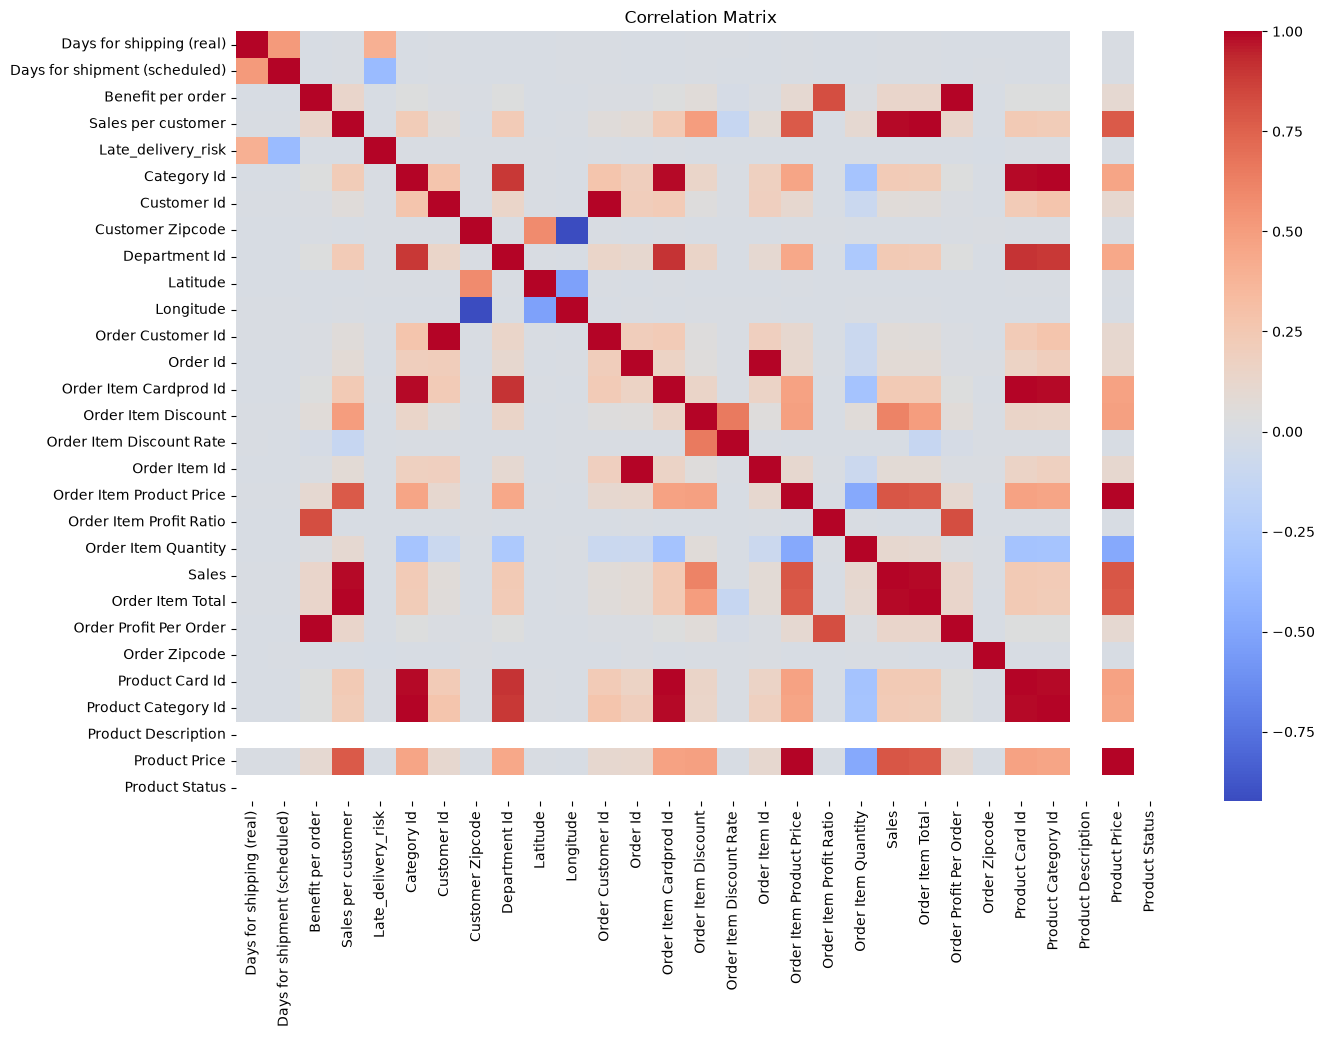

In [49]:
plt.figure(figsize=(15,10))
sns.heatmap(correlation_matrix, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [50]:
df["Sales"].corr(df["Order Item Total"])

np.float64(0.9897438811790847)

## Interpretation: Sales and Order Item Total are highly related, so they contain almost the same information. Also, actual shipping days have a positive relationship with late-delivery risk. Some variables are therefore related or repetitive, which should be considered during preprocessing.

## Time Analysis

In [52]:
df["order_date"] = pd.to_datetime(df["order date (DateOrders)"])
df["order_year"] = df["order_date"].dt.year
df["order_year"].value_counts().sort_index()

order_year
2015    62650
2016    62550
2017    53196
2018     2123
Name: count, dtype: int64

In [53]:
year_late = pd.crosstab(df["order_year"], df["Late_delivery_risk"], normalize="index") * 100
year_late

Late_delivery_risk,0,1
order_year,,
2015,45.136472,54.863528
2016,44.930456,55.069544
2017,45.552297,54.447703
2018,43.711729,56.288271


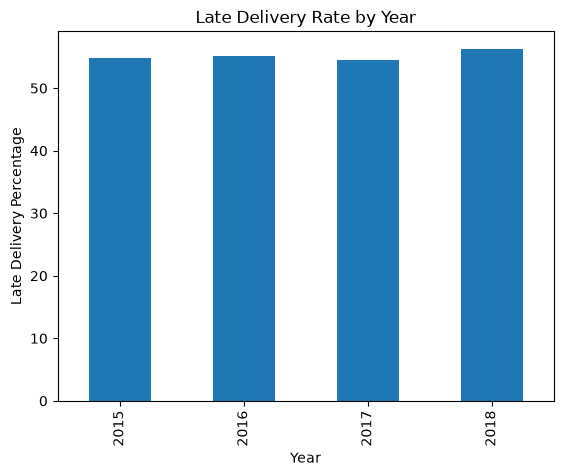

In [54]:
year_late[1].plot(kind="bar")
plt.xlabel("Year")
plt.ylabel("Late Delivery Percentage")
plt.title("Late Delivery Rate by Year")
plt.show()

## Interpretation: The late-risk percentage changes only slightly across years. The highest value is in 2018 at about 56.29%, while 2017 is about 54.45%. Time may have some effect, but the difference is not very large.

## Product Category vs Late Delivery

In [55]:
category_late = pd.crosstab(df["Category Name"], df["Late_delivery_risk"], normalize="index") * 100
category_late

Late_delivery_risk,0,1
Category Name,,
Accessories,43.033708,56.966292
As Seen on TV!,42.647059,57.352941
Baby,47.342995,52.657005
Baseball & Softball,44.778481,55.221519
Basketball,44.776119,55.223881
Books,43.456790,56.543210
Boxing & MMA,43.735225,56.264775
CDs,47.970480,52.029520
Cameras,41.891892,58.108108


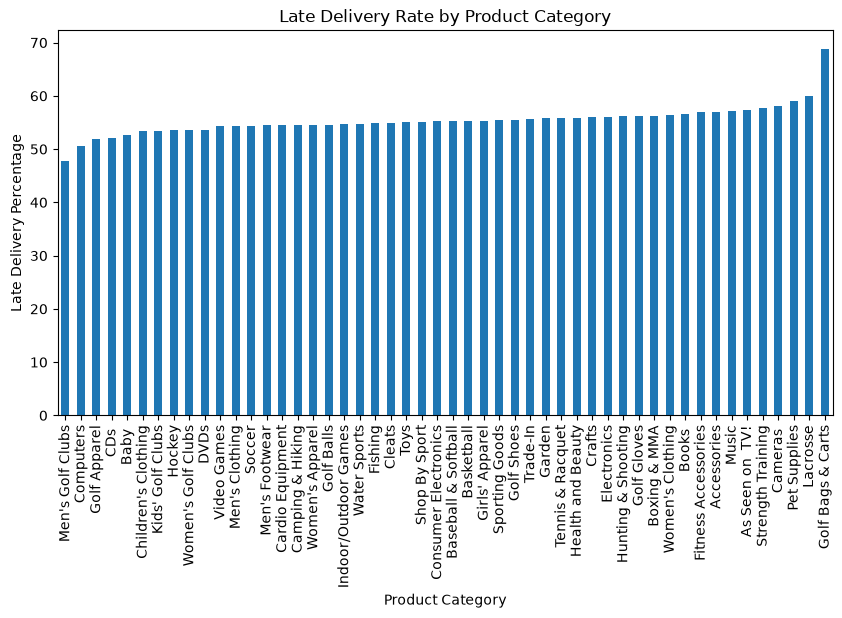

In [56]:
category_late[1].sort_values().plot(kind="bar", figsize=(10,5))
plt.xlabel("Product Category")
plt.ylabel("Late Delivery Percentage")
plt.title("Late Delivery Rate by Product Category")
plt.xticks(rotation=90)
plt.show()

## Interpretation: Late-risk percentages vary across product categories. For example, Golf Bags & Carts has a relatively high late-risk rate, while some categories are closer to 50%. This suggests product category may help the model identify different delivery patterns.

## Order Region vs Late Delivery

In [58]:
region_late = pd.crosstab(df["Order Region"], df["Late_delivery_risk"], normalize="index") * 100
region_late

Late_delivery_risk,0,1
Order Region,,
Canada,51.199166,48.800834
Caribbean,46.922337,53.077663
Central Africa,42.039356,57.960644
Central America,45.245404,54.754596
Central Asia,44.665461,55.334539
East Africa,44.060475,55.939525
East of USA,44.338395,55.661605
Eastern Asia,45.673077,54.326923
Eastern Europe,44.336735,55.663265


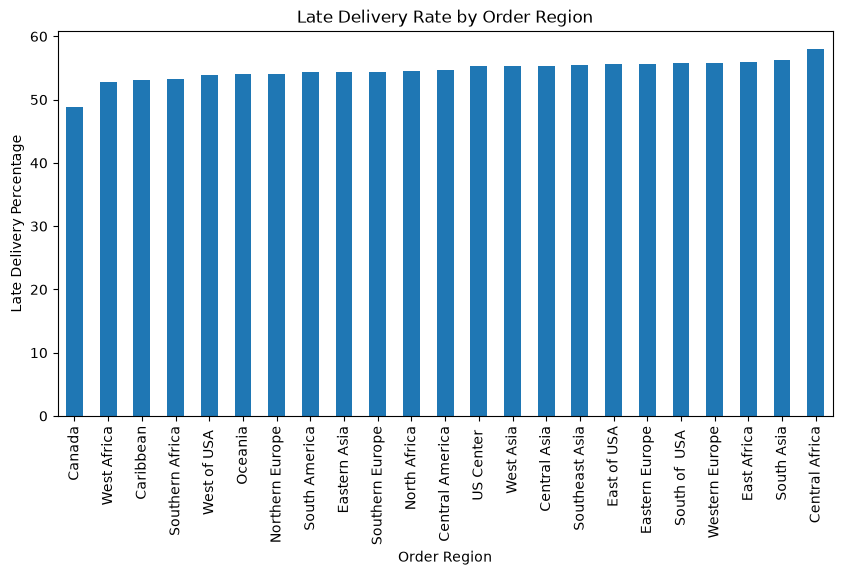

In [59]:
region_late[1].sort_values().plot(kind="bar", figsize=(10,5))
plt.xlabel("Order Region")
plt.ylabel("Late Delivery Percentage")
plt.title("Late Delivery Rate by Order Region")
plt.xticks(rotation=90)
plt.show()

## Interpretation: Late-risk percentages are different across regions. Central Africa and South Asia are among the higher-rate regions, while Canada is lower. Location-related variables may therefore help the model.

## Payment Type vs Late Delivery

In [60]:
df["Type"].value_counts()
payment_late = pd.crosstab(df["Type"], df["Late_delivery_risk"], normalize="index") * 100
payment_late


Late_delivery_risk,0,1
Type,,
CASH,43.367659,56.632341
DEBIT,42.782308,57.217692
PAYMENT,42.470941,57.529059
TRANSFER,51.456408,48.543592


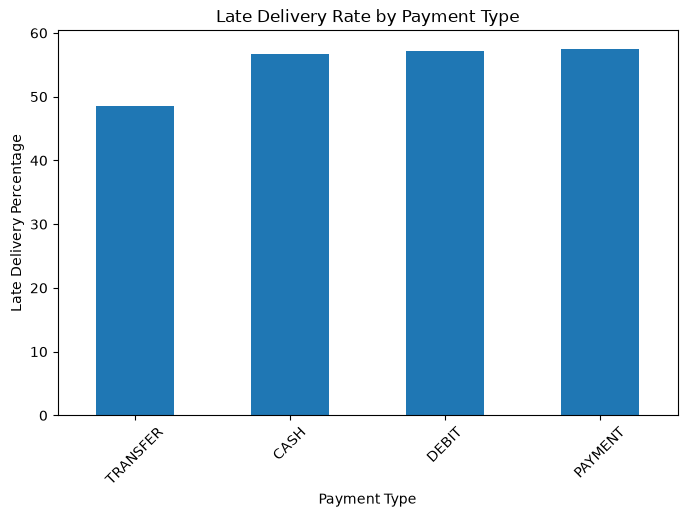

In [61]:
payment_late[1].sort_values().plot(kind="bar", figsize=(8,5))
plt.xlabel("Payment Type")
plt.ylabel("Late Delivery Percentage")
plt.title("Late Delivery Rate by Payment Type")
plt.xticks(rotation=45)
plt.show()

## Interpretation: Payment types show some difference. PAYMENT has about 57.53% late-risk, while TRANSFER has about 48.54%. The difference is not as large as shipping mode, but payment type can still be tested later.

## Month vs Late Delivery

In [62]:
df["month"] = df["order_date"].dt.month
month_late = pd.crosstab(df["month"], df["Late_delivery_risk"], normalize="index") * 100
month_late

Late_delivery_risk,0,1
month,,
1,45.341788,54.658212
2,45.447037,54.552963
3,44.745273,55.254727
4,45.720764,54.279236
5,45.261642,54.738358
6,45.174714,54.825286
7,45.942721,54.057279
8,44.205631,55.794369
9,44.702692,55.297308


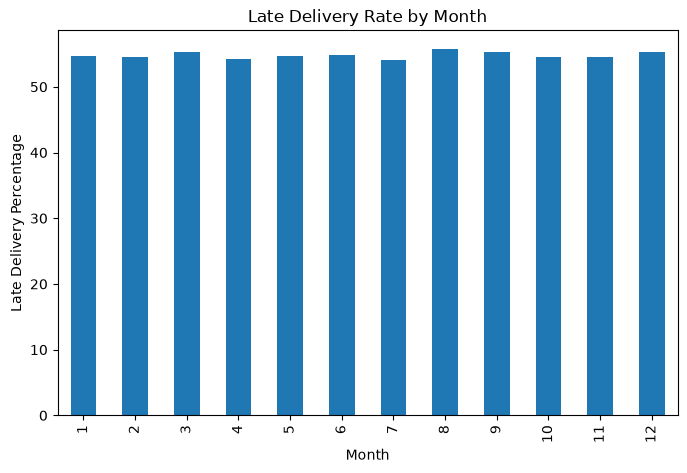

In [63]:
month_late[1].plot(kind="bar", figsize=(8,5))
plt.xlabel("Month")
plt.ylabel("Late Delivery Percentage")
plt.title("Late Delivery Rate by Month")
plt.show()

## Interpretation: Monthly late-risk rates are fairly close to each other. August is the highest at about 55.79%, while July is about 54.06%. Month does not show a very strong difference by itself.

## DATA PREPROCESSING

## Why preprocessing is needed
Part 3 will use this cleaned dataset for machine learning.
Some columns are removed because they are:
- personal/customer information,
- IDs,
- completely empty,
- post-delivery information, or
- information that can cause data leakage.


In [29]:
## fresh copy for preprocessing
df_model = pd.read_csv("DataCoSupplyChainDataset (1).csv", encoding="latin1")
print("Rows:", df_model.shape[0])
print("Columns:", df_model.shape[1])

Rows: 180519
Columns: 53


In [30]:
# Create date features
df_model["order_date"] = pd.to_datetime(df_model["order date (DateOrders)"])
df_model["order_year"] = df_model["order_date"].dt.year
df_model["order_month"] = df_model["order_date"].dt.month
df_model["order_day"] = df_model["order_date"].dt.day
df_model["order_weekday"] = df_model["order_date"].dt.dayofweek

In [53]:
# drop unncessary columns

In [31]:
columns_to_drop = ["Product Description","Order Zipcode","Product Status","Customer Email","Customer Password","Customer Fname","Customer Lname","Customer Street","Customer Id","Order Customer Id","Order Id","Order Item Id","Order Item Cardprod Id","Product Card Id","Product Category Id","Category Id","Department Id","Delivery Status","Days for shipping (real)","shipping date (DateOrders)","Order Status","Benefit per order","Order Profit Per Order","Order Item Profit Ratio","Order Item Total","order_date","order date (DateOrders)"]

In [32]:
df_model = df_model.drop(columns=columns_to_drop)

In [33]:
print("Rows:", df_model.shape[0])
print("Columns:", df_model.shape[1])
df_model.head()

Rows: 180519
Columns: 31


,Type,Days for shipment (scheduled),Sales per customer,Late_delivery_risk,Category Name,Customer City,Customer Country,Customer Segment,Customer State,Customer Zipcode,...,Order Region,Order State,Product Image,Product Name,Product Price,Shipping Mode,order_year,order_month,order_day,order_weekday
0,DEBIT,4,314.640015,0,Sporting Goods,Caguas,Puerto Rico,Consumer,PR,725.0,...,Southeast Asia,Java Occidental,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,Standard Class,2018,1,31,2
1,TRANSFER,4,311.359985,1,Sporting Goods,Caguas,Puerto Rico,Consumer,PR,725.0,...,South Asia,Rajastán,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,Standard Class,2018,1,13,5
2,CASH,4,309.720001,0,Sporting Goods,San Jose,EE. UU.,Consumer,CA,95125.0,...,South Asia,Rajastán,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,Standard Class,2018,1,13,5
3,DEBIT,4,304.809998,0,Sporting Goods,Los Angeles,EE. UU.,Home Office,CA,90027.0,...,Oceania,Queensland,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,Standard Class,2018,1,13,5
4,PAYMENT,4,298.250000,0,Sporting Goods,Caguas,Puerto Rico,Corporate,PR,725.0,...,Oceania,Queensland,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,Standard Class,2018,1,13,5


## Interpretation: The removed columns include identifiers, personal information and variables that are known only after the delivery process. Removing them helps avoid data leakage and makes the model more suitable for predicting late delivery at order placement.

In [34]:
# missing value
df_model.isnull().sum()
print("Total missing values:", df_model.isnull().sum().sum())

Total missing values: 3


In [35]:
for column in df_model.columns:
    if df_model[column].isnull().sum() > 0:
        if pd.api.types.is_numeric_dtype(df_model[column]):
            df_model[column] = df_model[column].fillna(df_model[column].median())
        else:
            df_model[column] = df_model[column].fillna(df_model[column].mode()[0])

In [36]:
print("Total missing values:", df_model.isnull().sum().sum())

Total missing values: 0


## Interpretation: Missing values are filled using the median for numerical columns and the mode for categorical columns. This keeps all observations available for modelling.

In [37]:
## convert categorical data into numeric
categorical_columns = df_model.select_dtypes(exclude=np.number).columns
print(categorical_columns)

Index(['Type', 'Category Name', 'Customer City', 'Customer Country',
       'Customer Segment', 'Customer State', 'Department Name', 'Market',
       'Order City', 'Order Country', 'Order Region', 'Order State',
       'Product Image', 'Product Name', 'Shipping Mode'],
      dtype='str')


## Interpretation: Categorical variables are converted into numerical dummy variables so that machine learning models can use them. The number of columns increases because categories such as product, location and shipping mode are represented by separate 0/1 columns.

In [38]:
df_model = pd.get_dummies(df_model, columns=categorical_columns, drop_first=True, dtype=int)

In [ ]:
print("Rows:", df_model.shape[0])
print("Columns:", df_model.shape[1])
print("Total missing values:", df_model.isnull().sum().sum())
print("Duplicate rows:", df_model.duplicated().sum())
df_model.head()

In [69]:
print("Late_delivery_risk" in df_model.columns)
df_model["Late_delivery_risk"].value_counts()

True


Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

## Conclusion of Part 2
- The dataset contains 180,519 order-item records and 53 original columns.
- Late delivery risk is reasonably balanced, with about 54.83% late-risk orders.
- Shipping mode shows the clearest relationship with late delivery.
- Customer segment and market show smaller differences.
- Sales has very few outliers and the average sales of late and non-late orders are almost the same.
- Product category, region, payment type and time show some differences in late delivery.
- Unnecessary, personal and leakage-related columns were removed before modelling.
- Missing values were handled and categorical variables were converted into numbers.

## PART 3 — FEATURE SELECTION & MODEL BUILDING

**Business question:** Can we tell, at the time an order is placed, whether it is at risk of being delivered late?

This part continues from Part 2. It uses two things that Part 2 already created:

- `df`  the original data (used here only for `Order Id` and a few checks)
- `df_model` — the cleaned and encoded data


In [39]:
# check that Part 2 has been run - we need df and df_model
print("df rows:", len(df))
print("df_model rows:", df_model.shape[0])
print("df_model columns:", df_model.shape[1])

df rows: 180519
df_model rows: 180519
df_model columns: 5798


In [40]:
# both tables must have the same rows in the same order
print((df["Late_delivery_risk"] == df_model["Late_delivery_risk"]).all())

True


## 3.1 Separate X and y

- **y** = `Late_delivery_risk` (1 = late, 0 = not late)
- **X** = everything else that is known when the order is placed

In [42]:
# target variable
y = df_model["Late_delivery_risk"]
round(y.value_counts(normalize=True) * 100, 2)

Late_delivery_risk
1    54.83
0    45.17
Name: proportion, dtype: float64

In [43]:
# all feature names after Part 2 encoding (target removed)
feature_names = df_model.columns.drop("Late_delivery_risk")
print("Features after Part 2 encoding:", len(feature_names))

Features after Part 2 encoding: 5797


## 3.2 Feature selection – step 1 (remove columns that do not help)

### Predict first

One-hot encoding in Part 2 created thousands of columns. Before running the next cells, think:

- Which text columns created most of these columns?
- Does a column like `Order City` with thousands of values help a model learn a general pattern?

We check the evidence first and then remove.

In [44]:
# how many different values do the text columns have?
df[["Order City", "Order State", "Order Country", "Customer City", "Customer State",
    "Product Name", "Product Image", "Category Name", "Order Region", "Market"]].nunique()

Order City        3597
Order State       1089
Order Country      164
Customer City      563
Customer State      46
Product Name       118
Product Image      118
Category Name       50
Order Region        23
Market               5
dtype: int64

In [45]:
# does every product name have exactly one product image?
df.groupby("Product Name")["Product Image"].nunique().max()

np.int64(1)

In [46]:
# shipping mode vs scheduled days - is it the same information?
pd.crosstab(df["Shipping Mode"], df["Days for shipment (scheduled)"])

Days for shipment (scheduled),0,1,2,4
Shipping Mode,,,,
First Class,0,27814,0,0
Same Day,9737,0,0,0
Second Class,0,0,35216,0
Standard Class,0,0,0,107752


In [47]:
# pairs of numeric columns that look like copies of each other
print("Product Price vs Order Item Product Price:", df["Product Price"].corr(df["Order Item Product Price"]))
print("Sales per customer vs Order Item Total:", df["Sales per customer"].corr(df["Order Item Total"]))
print("Sales per customer vs Sales:", df["Sales per customer"].corr(df["Sales"]))

Product Price vs Order Item Product Price: 1.0
Sales per customer vs Order Item Total: 0.9999999999999999
Sales per customer vs Sales: 0.9897438811790847


### What the checks show

- **Order City (3,597 values), Order State (1,089), Customer City (563), Order Country (164)** create most of the 5,797 columns. With so many values, each one covers only a small slice of the orders, so the model would memorise places instead of learning a pattern. Location is still covered by `Market`, `Order Region`, `Latitude` and `Longitude`.
- **Customer State (46)** – the customer's location is already described by `Latitude` and `Longitude`.
- **Product Name and Product Image** – every product has exactly one image, so both say the same thing. The product group is already described by `Category Name` and `Department Name`.
- **Days for shipment (scheduled)** – each shipping mode has exactly one scheduled value (Same Day 0, First Class 1, Second Class 2, Standard Class 4). It is the same information as `Shipping Mode`, so we keep the shipping mode columns only.
- **Order Item Product Price** is a copy of `Product Price` (correlation 1.0). **Sales per customer** is a copy of `Order Item Total` (correlation 1.0), which Part 2 already dropped as a near-copy of `Sales`.
- **Customer Zipcode** is a postal code stored as a number. A bigger zipcode does not mean "more" of anything.

In [48]:
# remove the dummy columns of the high-cardinality / repeated text columns
high_card_cols = ["Order City", "Order State", "Order Country", "Customer City",
                  "Customer State", "Product Name", "Product Image"]

for col_name in high_card_cols:
    dummy_cols = feature_names[feature_names.str.startswith(col_name + "_")]
    print(col_name, "->", len(dummy_cols), "dummy columns removed")
    feature_names = feature_names.drop(dummy_cols)

print("Features left:", len(feature_names))

Order City -> 3596 dummy columns removed
Order State -> 1088 dummy columns removed
Order Country -> 163 dummy columns removed
Customer City -> 562 dummy columns removed
Customer State -> 45 dummy columns removed
Product Name -> 117 dummy columns removed
Product Image -> 117 dummy columns removed
Features left: 109


In [49]:
# remove the repeated numeric columns and the zipcode (it is a code, not a measurement)
other_cols_to_remove = ["Customer Zipcode", "Order Item Product Price",
                        "Sales per customer", "Days for shipment (scheduled)"]
feature_names = feature_names.drop(other_cols_to_remove)
print("Features left:", len(feature_names))

Features left: 105


In [50]:
# build X with the selected features only
X = df_model[feature_names]
print(X.shape)
X.head()

(180519, 105)


,Latitude,Longitude,Order Item Discount,Order Item Discount Rate,Order Item Quantity,Sales,Product Price,order_year,order_month,order_day,...,Order Region_Southern Africa,Order Region_Southern Europe,Order Region_US Center,Order Region_West Africa,Order Region_West Asia,Order Region_West of USA,Order Region_Western Europe,Shipping Mode_Same Day,Shipping Mode_Second Class,Shipping Mode_Standard Class
0,18.251453,-66.037056,13.110000,0.04,1,327.75,327.75,2018,1,31,...,0,0,0,0,0,0,0,0,0,1
1,18.279451,-66.037064,16.389999,0.05,1,327.75,327.75,2018,1,13,...,0,0,0,0,0,0,0,0,0,1
2,37.292233,-121.881279,18.030001,0.06,1,327.75,327.75,2018,1,13,...,0,0,0,0,0,0,0,0,0,1
3,34.125946,-118.291016,22.940001,0.07,1,327.75,327.75,2018,1,13,...,0,0,0,0,0,0,0,0,0,1
4,18.253769,-66.037048,29.500000,0.09,1,327.75,327.75,2018,1,13,...,0,0,0,0,0,0,0,0,0,1


In [51]:
# list of features that go into the models
print(X.columns.tolist())

['Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Quantity', 'Sales', 'Product Price', 'order_year', 'order_month', 'order_day', 'order_weekday', 'Type_DEBIT', 'Type_PAYMENT', 'Type_TRANSFER', 'Category Name_As Seen on  TV!', 'Category Name_Baby ', 'Category Name_Baseball & Softball', 'Category Name_Basketball', 'Category Name_Books ', 'Category Name_Boxing & MMA', 'Category Name_CDs ', 'Category Name_Cameras ', 'Category Name_Camping & Hiking', 'Category Name_Cardio Equipment', "Category Name_Children's Clothing", 'Category Name_Cleats', 'Category Name_Computers', 'Category Name_Consumer Electronics', 'Category Name_Crafts', 'Category Name_DVDs', 'Category Name_Electronics', 'Category Name_Fishing', 'Category Name_Fitness Accessories', 'Category Name_Garden', "Category Name_Girls' Apparel", 'Category Name_Golf Apparel', 'Category Name_Golf Bags & Carts', 'Category Name_Golf Balls', 'Category Name_Golf Gloves', 'Category Name_Golf Shoes', 'Categor

## 3.3 Train-test split

### Why the split is done order-wise

The test set should represent **unseen orders**.

In this dataset one row is one **order item**, and one order can have several items. Check the next two cells before reading further.

In [52]:
# how many items per order on average?
print("Rows (order items):", len(df))
print("Orders:", df["Order Id"].nunique())
print("Items per order:", round(len(df) / df["Order Id"].nunique(), 2))

Rows (order items): 180519
Orders: 65752
Items per order: 2.75


In [53]:
# does every item of an order have the same target value?
df.groupby("Order Id")["Late_delivery_risk"].nunique().max()

np.int64(1)

## All items of one order are late together or on time together (the answer above is 1).

If rows are split randomly, items of the same order land in both train and test. The model then sees the answer for that order during training, and the test score looks better than it really is. This is a form of **data leakage**.

So we split the **order ids** 80/20 and keep all items of an order on the same side. `Order Id` is used only to make the split. It is not a feature.

In [56]:
from sklearn.model_selection import train_test_split

In [57]:
# split the order ids into train and test
order_ids = df["Order Id"].unique()

train_order_ids, test_order_ids = train_test_split(
    order_ids,
    test_size=0.20,
    random_state=42)

# rows that belong to train orders and test orders
train_rows = df["Order Id"].isin(train_order_ids)
test_rows = df["Order Id"].isin(test_order_ids)

X_train_raw = X[train_rows]
X_test_raw = X[test_rows]
y_train_raw = y[train_rows]
y_test_raw = y[test_rows]

print("Training observations:", len(X_train_raw))
print("Test observations:", len(X_test_raw))

Training observations: 144305
Test observations: 36214


In [58]:
# is the late share similar in train and test?
print("Late share in train:", round(y_train_raw.mean() * 100, 2))
print("Late share in test:", round(y_test_raw.mean() * 100, 2))

Late share in train: 54.87
Late share in test: 54.65


### Observe

- 144,305 rows go to training and 36,214 to testing.
- The late share is 54.87% in train and 54.65% in test, so both sides look alike.

**Class imbalance:** the classes are about 55/45. This is close to balanced, so SMOTE or class weights are not used. We still read precision, recall and F1 for the late class and not accuracy alone.

## 3.4 Scaling

Logistic Regression works better when all features are on a similar scale (Sales is in hundreds, dummies are 0/1).

A key rule:

> **Fit the scaler on training data; use the learned scaling on test data.**

Tree-based models do not need scaling, so they use the raw data.

In [59]:
from sklearn.preprocessing import StandardScaler

In [60]:
# fit on train, apply on test
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(144305, 105)
(36214, 105)


## 3.5 Model 1 – Logistic Regression (baseline)

### Why this model

The target has two outcomes (late / not late), so this is a binary classification problem. Logistic Regression is the simplest model for that. It is fast, easy to explain, and gives a baseline that the other models have to beat.

### Before running

Predict:

- Will accuracy be much higher than 55% (the share of late orders)?
- Will recall for late orders be high or low?

In [61]:
from sklearn.linear_model import LogisticRegression

In [62]:
# build regression model lr ...
lr = LogisticRegression(max_iter=1000)

# train the model...
lr.fit(X_train_scaled, y_train_raw)

# generate y_lr_pred and the probability of late delivery
y_lr_pred = lr.predict(X_test_scaled)
y_lr_proba = lr.predict_proba(X_test_scaled)[:, 1]

In [63]:
from sklearn import metrics

In [64]:
# generate confusion matrix and classification report
cm_lr = metrics.confusion_matrix(y_test_raw, y_lr_pred)
print(cm_lr)

print(metrics.classification_report(y_test_raw, y_lr_pred))
print("AUC:", metrics.roc_auc_score(y_test_raw, y_lr_proba))

[[14337  2086]
 [ 9125 10666]]
              precision    recall  f1-score   support

           0       0.61      0.87      0.72     16423
           1       0.84      0.54      0.66     19791

    accuracy                           0.69     36214
   macro avg       0.72      0.71      0.69     36214
weighted avg       0.73      0.69      0.68     36214

AUC: 0.7355017609228026


### Interpret the baseline

Focus on the **late class (1)**.

- **Accuracy 0.69, AUC 0.736.** Better than the 55% we would get by calling every order late.
- **Precision 0.84** – when the model flags an order, it is usually right. Only 2,086 on-time orders were flagged wrongly.
- **Recall 0.54** – the model misses 9,125 of the 19,791 late orders. Almost half of the late orders get no warning.

**Business meaning:** the alerts can be trusted, but many late orders slip through.

## 3.6 Model 2 – Decision Tree

### Why this model

A Decision Tree learns if-then rules (for example: "if shipping mode is First Class then late"). Operations teams can read such rules easily. It also handles 0/1 dummy columns and numeric columns together without scaling.

### Before running

A tree with no depth limit keeps splitting until it fits the training data almost perfectly. Will that help or hurt on unseen orders?

In [65]:
from sklearn.tree import DecisionTreeClassifier

In [66]:
# build, train and predict
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train_raw, y_train_raw)

y_dt_pred = dt.predict(X_test_raw)
y_dt_proba = dt.predict_proba(X_test_raw)[:, 1]

In [67]:
# build confusion matrix and classification report
cm_dt = metrics.confusion_matrix(y_test_raw, y_dt_pred)
print(cm_dt)

print(metrics.classification_report(y_test_raw, y_dt_pred))
print("AUC:", metrics.roc_auc_score(y_test_raw, y_dt_proba))

[[ 9390  7033]
 [ 7047 12744]]
              precision    recall  f1-score   support

           0       0.57      0.57      0.57     16423
           1       0.64      0.64      0.64     19791

    accuracy                           0.61     36214
   macro avg       0.61      0.61      0.61     36214
weighted avg       0.61      0.61      0.61     36214

AUC: 0.6078440884863581


In [68]:
# compare with accuracy on the training data
print("Train accuracy:", metrics.accuracy_score(y_train_raw, dt.predict(X_train_raw)))
print("Test accuracy:", metrics.accuracy_score(y_test_raw, y_dt_pred))

Train accuracy: 1.0
Test accuracy: 0.6112000883636163


### Interpret the Decision Tree

- **Train accuracy 1.00 vs test accuracy 0.61.** The tree has memorised the training orders. This is overfitting.
- **AUC 0.61** – the weakest of all models so far.

The fix is to limit how deep the tree can grow. That is done in Part 4.

## 3.7 Model 3 – Random Forest

### Why this model

Random Forest is an **ensemble method**.

> **Many trees → each gives a prediction → combine the predictions**

Averaging many trees reduces the overfitting of a single tree. It also gives a feature importance ranking, which we need for feature selection.

In [69]:
from sklearn.ensemble import RandomForestClassifier

In [70]:
# build, train and predict
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

rf.fit(X_train_raw, y_train_raw)

y_rf_pred = rf.predict(X_test_raw)
y_rf_proba = rf.predict_proba(X_test_raw)[:, 1]

In [71]:
# build confusion matrix and classification report
cm_rf = metrics.confusion_matrix(y_test_raw, y_rf_pred)
print(cm_rf)

print(metrics.classification_report(y_test_raw, y_rf_pred))
print("AUC:", metrics.roc_auc_score(y_test_raw, y_rf_proba))

[[12410  4013]
 [ 7704 12087]]
              precision    recall  f1-score   support

           0       0.62      0.76      0.68     16423
           1       0.75      0.61      0.67     19791

    accuracy                           0.68     36214
   macro avg       0.68      0.68      0.68     36214
weighted avg       0.69      0.68      0.68     36214

AUC: 0.7264742950608505


### Interpret the Random Forest

- **Accuracy 0.68, AUC 0.726.** Much better than the single tree, so combining many trees did reduce the overfitting.
- **Recall 0.61** – it catches 12,087 late orders, more than Logistic Regression (10,666).
- **Precision 0.75** – but it raises 4,013 false alarms, about twice as many as Logistic Regression (2,086).

So Random Forest finds more late orders and pays for it with more false alarms.

## 3.8 Model 4 – Gradient Boosting

### Why this model

Gradient Boosting also uses many trees, but builds them one after another.

> **Build a model → look at the remaining error → build the next model to reduce that error → repeat**

It usually does well on table-type business data with a mix of numeric and category columns, which is what we have.

In [72]:
from sklearn.ensemble import GradientBoostingClassifier

In [73]:
# build, train and predict
gb = GradientBoostingClassifier(random_state=42)

gb.fit(X_train_raw, y_train_raw)

y_gb_pred = gb.predict(X_test_raw)
y_gb_proba = gb.predict_proba(X_test_raw)[:, 1]

In [74]:
# build confusion matrix and classification report
cm_gb = metrics.confusion_matrix(y_test_raw, y_gb_pred)
print(cm_gb)

print(metrics.classification_report(y_test_raw, y_gb_pred))
print("AUC:", metrics.roc_auc_score(y_test_raw, y_gb_proba))

[[14138  2285]
 [ 8880 10911]]
              precision    recall  f1-score   support

           0       0.61      0.86      0.72     16423
           1       0.83      0.55      0.66     19791

    accuracy                           0.69     36214
   macro avg       0.72      0.71      0.69     36214
weighted avg       0.73      0.69      0.69     36214

AUC: 0.7390778157717828


### Interpret Gradient Boosting

- **Accuracy 0.69, AUC 0.739.** The highest AUC of the four models, but only slightly above Logistic Regression (0.736).
- **Precision 0.83, recall 0.55.** Same behaviour as Logistic Regression: careful alerts, many late orders missed (8,880).

In [75]:
# feature importance from the random forest
importance = pd.Series(
    rf.feature_importances_,
    index=X_train_raw.columns
).sort_values(ascending=False)

print(importance.head(20))

Shipping Mode_Standard Class    0.149174
Latitude                        0.099631
Longitude                       0.094350
order_day                       0.078088
Order Item Discount             0.065506
Order Item Discount Rate        0.055883
order_weekday                   0.050118
order_month                     0.049774
Sales                           0.034429
Shipping Mode_Second Class      0.025277
Product Price                   0.023394
Order Item Quantity             0.019350
Shipping Mode_Same Day          0.018427
order_year                      0.017902
Customer Segment_Corporate      0.014911
Customer Segment_Home Office    0.012696
Customer Country_Puerto Rico    0.009127
Type_DEBIT                      0.008540
Type_TRANSFER                   0.007660
Type_PAYMENT                    0.007031
dtype: float64


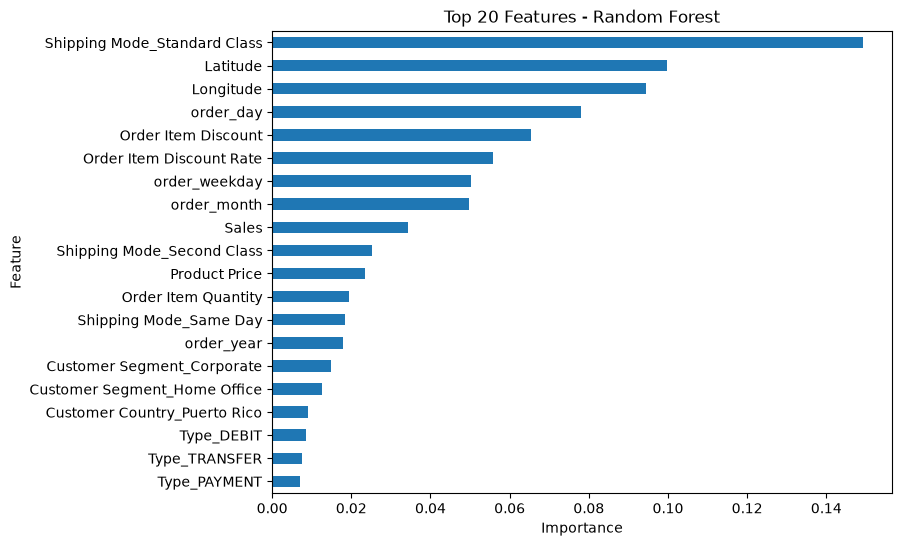

In [76]:
importance.head(20).sort_values().plot(kind="barh", figsize=(8,6))
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features - Random Forest")
plt.show()

In [77]:
# how much of the total importance do the top 20 features hold?
print("Top 20 share:", round(importance.head(20).sum() * 100, 2))
print("Features with importance below 0.005:", (importance < 0.005).sum())

Top 20 share: 84.13
Features with importance below 0.005: 79


In [78]:
# keep the top 20 features for the refinement step in Part 4
top_features = importance.head(20).index.tolist()
print(top_features)

['Shipping Mode_Standard Class', 'Latitude', 'Longitude', 'order_day', 'Order Item Discount', 'Order Item Discount Rate', 'order_weekday', 'order_month', 'Sales', 'Shipping Mode_Second Class', 'Product Price', 'Order Item Quantity', 'Shipping Mode_Same Day', 'order_year', 'Customer Segment_Corporate', 'Customer Segment_Home Office', 'Customer Country_Puerto Rico', 'Type_DEBIT', 'Type_TRANSFER', 'Type_PAYMENT']


### Observe and interpret

- `Shipping Mode_Standard Class` is the top feature (0.149). This matches Part 2, where shipping mode showed by far the biggest gap in late rate.
- `Latitude`, `Longitude`, `order_day` and the discount columns come next. **Read this with care:** a Random Forest tends to give more importance to numeric columns with many different values, because they offer many places to split. Their rank may be overstated. We check again with the final model in Part 5.
- The top 20 features hold 84.13% of the total importance. 79 of the 105 features are below 0.005.
- None of the `Category Name`, `Department Name`, `Market` or `Order Region` columns reached the top 20.

**Decision:** the top 20 features are kept as `top_features` and tested as a smaller model in Part 4.

# PART 4 — MODEL EVALUATION & REFINEMENT

**Business question:** Which model should DataCo trust, and can it be made better?

### Which metric matters here?

Focus on the **late class (1)**.

- **Recall** – out of all orders that were really late, how many did the model catch? Low recall means late orders slip through with no warning.
- **Precision** – out of all orders the model flagged, how many were really late? Low precision means the team spends effort on orders that were fine.
- **F1** – balance of the two.
- **AUC** – how well the model ranks risky orders above safe ones, across all cut-offs.
- **Accuracy** – overall correct share. The classes are 55/45, so a model that says "late" for every order already gets about 55%.

## 4.1 Compare all models in one table

In [81]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting'
    ],
    'Accuracy': [
        metrics.accuracy_score(y_test_raw, y_lr_pred),
        metrics.accuracy_score(y_test_raw, y_dt_pred),
        metrics.accuracy_score(y_test_raw, y_rf_pred),
        metrics.accuracy_score(y_test_raw, y_gb_pred)
    ],
    'Precision': [
        metrics.precision_score(y_test_raw, y_lr_pred),
        metrics.precision_score(y_test_raw, y_dt_pred),
        metrics.precision_score(y_test_raw, y_rf_pred),
        metrics.precision_score(y_test_raw, y_gb_pred)
    ],
    'Recall': [
        metrics.recall_score(y_test_raw, y_lr_pred),
        metrics.recall_score(y_test_raw, y_dt_pred),
        metrics.recall_score(y_test_raw, y_rf_pred),
        metrics.recall_score(y_test_raw, y_gb_pred)
    ],
    'F1': [
        metrics.f1_score(y_test_raw, y_lr_pred),
        metrics.f1_score(y_test_raw, y_dt_pred),
        metrics.f1_score(y_test_raw, y_rf_pred),
        metrics.f1_score(y_test_raw, y_gb_pred)
    ],
    'AUC': [
        metrics.roc_auc_score(y_test_raw, y_lr_proba),
        metrics.roc_auc_score(y_test_raw, y_dt_proba),
        metrics.roc_auc_score(y_test_raw, y_rf_proba),
        metrics.roc_auc_score(y_test_raw, y_gb_proba)
    ]
})

results.round(4)

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.6904,0.8364,0.5389,0.6555,0.7355
1,Decision Tree,0.6112,0.6444,0.6439,0.6442,0.6078
2,Random Forest,0.6765,0.7507,0.6107,0.6735,0.7265
3,Gradient Boosting,0.6917,0.8268,0.5513,0.6615,0.7391


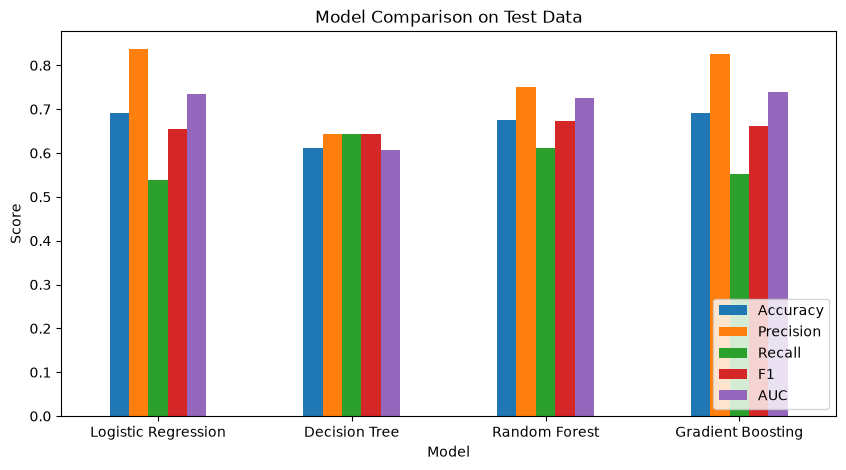

In [82]:
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "AUC"]].plot(kind="bar", figsize=(10,5))
plt.ylabel("Score")
plt.title("Model Comparison on Test Data")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

## 4.2 ROC curves

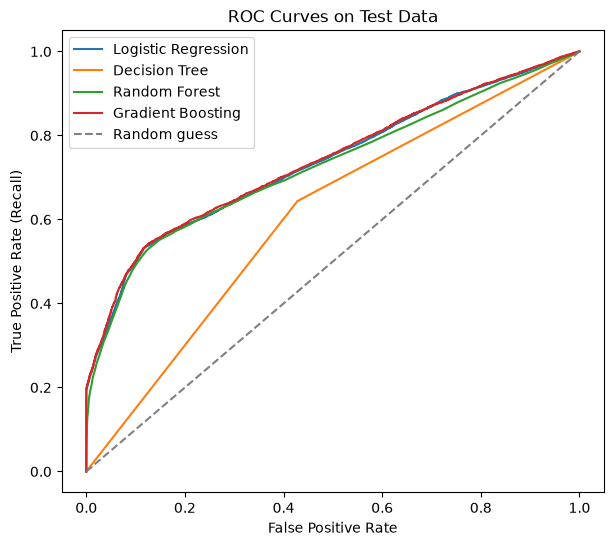

In [83]:
# ROC curve for each model
fpr_lr, tpr_lr, thresholds_lr = metrics.roc_curve(y_test_raw, y_lr_proba)
fpr_dt, tpr_dt, thresholds_dt = metrics.roc_curve(y_test_raw, y_dt_proba)
fpr_rf, tpr_rf, thresholds_rf = metrics.roc_curve(y_test_raw, y_rf_proba)
fpr_gb, tpr_gb, thresholds_gb = metrics.roc_curve(y_test_raw, y_gb_proba)

plt.figure(figsize=(7,6))
plt.plot(fpr_lr, tpr_lr, label="Logistic Regression")
plt.plot(fpr_dt, tpr_dt, label="Decision Tree")
plt.plot(fpr_rf, tpr_rf, label="Random Forest")
plt.plot(fpr_gb, tpr_gb, label="Gradient Boosting")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves on Test Data")
plt.legend()
plt.show()

## 4.3 Confusion matrices

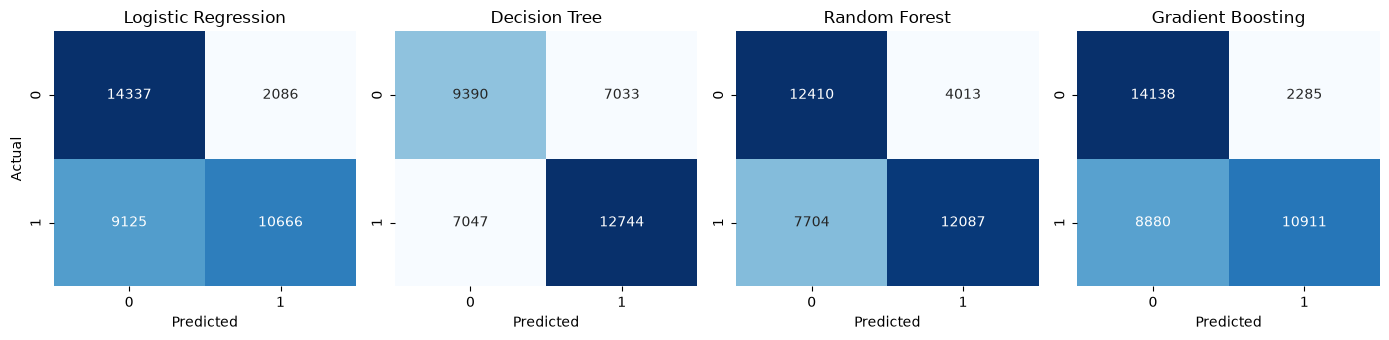

In [84]:
# confusion matrix of all four models side by side
plt.figure(figsize=(14,3.5))

plt.subplot(1, 4, 1)
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.subplot(1, 4, 2)
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Decision Tree")
plt.xlabel("Predicted")

plt.subplot(1, 4, 3)
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Random Forest")
plt.xlabel("Predicted")

plt.subplot(1, 4, 4)
sns.heatmap(cm_gb, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Gradient Boosting")
plt.xlabel("Predicted")

plt.tight_layout()
plt.show()

## 4.4 Which model is best?

**Finding:** Gradient Boosting is the best overall model, but the margin is small.

**Evidence:**

- Highest AUC (0.7391) and highest accuracy (0.6917). Logistic Regression is very close (AUC 0.7355, accuracy 0.6904).
- Random Forest has the highest recall (0.6107) and F1 (0.6735), but a lower AUC (0.7265) and the most false alarms after the Decision Tree (4,013 against 2,285 for Gradient Boosting).
- The Decision Tree is clearly the weakest (AUC 0.6078).

**Interpretation:** three very different models all end up near 0.69 accuracy. When that happens, the limit usually comes from the information in the data and not from the algorithm. All of them show the same pattern: high precision and low recall for late orders.

**Action:** Gradient Boosting goes forward to refinement because it ranks risky orders best (AUC). The main thing to improve is recall.

## 4.5 Refinement – set up a validation set

We now try different versions of the model. If we pick the best version by looking at the test score, the test set is no longer "unseen".

So we cut a **validation set** out of the training orders. All versions are compared on validation. The test set is used only once at the end.

In [85]:
# split the training orders again: sub-train and validation
subtrain_order_ids, val_order_ids = train_test_split(
    train_order_ids,
    test_size=0.20,
    random_state=42)

subtrain_rows = df["Order Id"].isin(subtrain_order_ids)
val_rows = df["Order Id"].isin(val_order_ids)

X_subtrain = X[subtrain_rows]
X_val = X[val_rows]
y_subtrain = y[subtrain_rows]
y_val = y[val_rows]

print("Sub-train observations:", len(X_subtrain))
print("Validation observations:", len(X_val))

Sub-train observations: 115231
Validation observations: 29074


### Version 1 – Gradient Boosting, default settings, all selected features

Same model as in 3.8, trained on sub-train so that it can be compared fairly with the other versions.

In [86]:
# build, train and predict on validation
gb_v1 = GradientBoostingClassifier(random_state=42)

gb_v1.fit(X_subtrain, y_subtrain)

y_val_v1_pred = gb_v1.predict(X_val)
y_val_v1_proba = gb_v1.predict_proba(X_val)[:, 1]

print(metrics.classification_report(y_val, y_val_v1_pred))
print("AUC:", metrics.roc_auc_score(y_val, y_val_v1_proba))

              precision    recall  f1-score   support

           0       0.61      0.86      0.72     12961
           1       0.83      0.57      0.67     16113

    accuracy                           0.70     29074
   macro avg       0.72      0.71      0.70     29074
weighted avg       0.73      0.70      0.69     29074

AUC: 0.7405773694580535


### Version 2 – feature refinement (top 20 features only)

**What changed:** the model gets only the 20 most important features from 3.9.

**Why:** a model with fewer inputs is easier to explain and to run. If the score stays the same, the other features were not adding anything.

### Predict first

Will the score drop when most of the features are taken away?

In [114]:
# keep only the top features
X_subtrain_top = X_subtrain[top_features]
X_val_top = X_val[top_features]

gb_v2 = GradientBoostingClassifier(random_state=42)

gb_v2.fit(X_subtrain_top, y_subtrain)

y_val_v2_pred = gb_v2.predict(X_val_top)
y_val_v2_proba = gb_v2.predict_proba(X_val_top)[:, 1]

print(metrics.classification_report(y_val, y_val_v2_pred))
print("AUC:", metrics.roc_auc_score(y_val, y_val_v2_proba))

              precision    recall  f1-score   support

           0       0.61      0.86      0.72     12961
           1       0.83      0.57      0.67     16113

    accuracy                           0.70     29074
   macro avg       0.72      0.71      0.69     29074
weighted avg       0.73      0.70      0.69     29074

AUC: 0.7417922841274446


### Version 3 – hyperparameter tuning (tree depth)

**What changed:** `max_depth`, which controls how detailed each tree is allowed to be.

**Why:** shallow trees may miss patterns, deep trees may memorise noise. We try a few values and keep the one that does best on validation.

In [115]:
# try different depths for gradient boosting
for depth in [2, 3, 4, 5]:
    gb_try = GradientBoostingClassifier(max_depth=depth, random_state=42)
    gb_try.fit(X_subtrain_top, y_subtrain)
    y_try_pred = gb_try.predict(X_val_top)
    y_try_proba = gb_try.predict_proba(X_val_top)[:, 1]
    print("max_depth:", depth,
          "| AUC:", round(metrics.roc_auc_score(y_val, y_try_proba), 4),
          "| F1:", round(metrics.f1_score(y_val, y_try_pred), 4),
          "| Accuracy:", round(metrics.accuracy_score(y_val, y_try_pred), 4))

max_depth: 2 | AUC: 0.7416 | F1: 0.6749 | Accuracy: 0.6955
max_depth: 3 | AUC: 0.7418 | F1: 0.6741 | Accuracy: 0.6963
max_depth: 4 | AUC: 0.74 | F1: 0.672 | Accuracy: 0.6953
max_depth: 5 | AUC: 0.7385 | F1: 0.6727 | Accuracy: 0.6942


In [116]:
# version 3 with the depth chosen from the loop above
gb_v3 = GradientBoostingClassifier(max_depth=3, random_state=42)

gb_v3.fit(X_subtrain_top, y_subtrain)

y_val_v3_pred = gb_v3.predict(X_val_top)
y_val_v3_proba = gb_v3.predict_proba(X_val_top)[:, 1]

print(metrics.classification_report(y_val, y_val_v3_pred))
print("AUC:", metrics.roc_auc_score(y_val, y_val_v3_proba))

              precision    recall  f1-score   support

           0       0.61      0.86      0.72     12961
           1       0.83      0.57      0.67     16113

    accuracy                           0.70     29074
   macro avg       0.72      0.71      0.69     29074
weighted avg       0.73      0.70      0.69     29074

AUC: 0.7417922841274446


### Same tuning idea for the other tree models

The Decision Tree in 3.6 was clearly overfitting. Limiting its depth is the direct fix. We do the same check for Random Forest.

In [117]:
# try different depths for the decision tree
for depth in [3, 5, 8, 12]:
    dt_try = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt_try.fit(X_subtrain, y_subtrain)
    y_try_pred = dt_try.predict(X_val)
    y_try_proba = dt_try.predict_proba(X_val)[:, 1]
    print("max_depth:", depth,
          "| AUC:", round(metrics.roc_auc_score(y_val, y_try_proba), 4),
          "| F1:", round(metrics.f1_score(y_val, y_try_pred), 4),
          "| Accuracy:", round(metrics.accuracy_score(y_val, y_try_pred), 4))

max_depth: 3 | AUC: 0.7377 | F1: 0.669 | Accuracy: 0.6966
max_depth: 5 | AUC: 0.7381 | F1: 0.6758 | Accuracy: 0.6955
max_depth: 8 | AUC: 0.7285 | F1: 0.6714 | Accuracy: 0.6865
max_depth: 12 | AUC: 0.7148 | F1: 0.6674 | Accuracy: 0.6793


In [118]:
# try different depths for the random forest
for depth in [5, 10, 15, 20]:
    rf_try = RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    rf_try.fit(X_subtrain, y_subtrain)
    y_try_pred = rf_try.predict(X_val)
    y_try_proba = rf_try.predict_proba(X_val)[:, 1]
    print("max_depth:", depth,
          "| AUC:", round(metrics.roc_auc_score(y_val, y_try_proba), 4),
          "| F1:", round(metrics.f1_score(y_val, y_try_pred), 4),
          "| Accuracy:", round(metrics.accuracy_score(y_val, y_try_pred), 4))

max_depth: 5 | AUC: 0.7218 | F1: 0.6836 | Accuracy: 0.6886
max_depth: 10 | AUC: 0.7269 | F1: 0.6812 | Accuracy: 0.6931
max_depth: 15 | AUC: 0.7352 | F1: 0.6814 | Accuracy: 0.6945
max_depth: 20 | AUC: 0.736 | F1: 0.6811 | Accuracy: 0.6934


In [119]:
# tuned decision tree and tuned random forest (depth chosen from the loops above)
dt_v2 = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_v2.fit(X_subtrain, y_subtrain)
y_val_dt_v2_pred = dt_v2.predict(X_val)
y_val_dt_v2_proba = dt_v2.predict_proba(X_val)[:, 1]

rf_v2 = RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
rf_v2.fit(X_subtrain, y_subtrain)
y_val_rf_v2_pred = rf_v2.predict(X_val)
y_val_rf_v2_proba = rf_v2.predict_proba(X_val)[:, 1]

### Version 4 – change the decision cut-off (threshold)

**What changed:** by default an order is flagged as late when the predicted probability is 0.50 or more. Here we try lower cut-offs. The model itself is the same as Version 3.

**Why:** the business wants to catch late orders *before* they happen. A lower cut-off flags more orders, so recall goes up and precision goes down.

### Predict first

How many more late orders will be caught at 0.40, and how many more false alarms will that cost?

In [120]:
# try different cut-offs on the version 3 probabilities
for cutoff in [0.30, 0.35, 0.40, 0.45, 0.50]:
    y_try_pred = (y_val_v3_proba >= cutoff).astype(int)
    print("cut-off:", cutoff,
          "| Precision:", round(metrics.precision_score(y_val, y_try_pred), 4),
          "| Recall:", round(metrics.recall_score(y_val, y_try_pred), 4),
          "| F1:", round(metrics.f1_score(y_val, y_try_pred), 4),
          "| Orders flagged %:", round(y_try_pred.mean() * 100, 1))

cut-off: 0.3 | Precision: 0.5556 | Recall: 0.9939 | F1: 0.7128 | Orders flagged %: 99.1
cut-off: 0.35 | Precision: 0.5824 | Recall: 0.9219 | F1: 0.7138 | Orders flagged %: 87.7
cut-off: 0.4 | Precision: 0.6846 | Recall: 0.7158 | F1: 0.6999 | Orders flagged %: 57.9
cut-off: 0.45 | Precision: 0.8151 | Recall: 0.5829 | F1: 0.6797 | Orders flagged %: 39.6
cut-off: 0.5 | Precision: 0.8317 | Recall: 0.5667 | F1: 0.6741 | Orders flagged %: 37.8


In [121]:
# version 4 = version 3 model with cut-off 0.40
y_val_v4_pred = (y_val_v3_proba >= 0.40).astype(int)

cm_val_v4 = metrics.confusion_matrix(y_val, y_val_v4_pred)
print(cm_val_v4)

print(metrics.classification_report(y_val, y_val_v4_pred))

[[ 7647  5314]
 [ 4579 11534]]
              precision    recall  f1-score   support

           0       0.63      0.59      0.61     12961
           1       0.68      0.72      0.70     16113

    accuracy                           0.66     29074
   macro avg       0.66      0.65      0.65     29074
weighted avg       0.66      0.66      0.66     29074



## 4.6 All versions in one table (validation data)

In [122]:
results_versions = pd.DataFrame({
    'Version': [
        'DT v1 - default',
        'DT v2 - depth tuned',
        'RF v1 - default',
        'RF v2 - depth tuned',
        'GB v1 - default, all features',
        'GB v2 - top 20 features',
        'GB v3 - top 20 + depth tuned',
        'GB v4 - v3 with cut-off 0.40'
    ],
    'Accuracy': [
        metrics.accuracy_score(y_val, y_val_dt_v1_pred),
        metrics.accuracy_score(y_val, y_val_dt_v2_pred),
        metrics.accuracy_score(y_val, y_val_rf_v1_pred),
        metrics.accuracy_score(y_val, y_val_rf_v2_pred),
        metrics.accuracy_score(y_val, y_val_v1_pred),
        metrics.accuracy_score(y_val, y_val_v2_pred),
        metrics.accuracy_score(y_val, y_val_v3_pred),
        metrics.accuracy_score(y_val, y_val_v4_pred)
    ],
    'Precision': [
        metrics.precision_score(y_val, y_val_dt_v1_pred),
        metrics.precision_score(y_val, y_val_dt_v2_pred),
        metrics.precision_score(y_val, y_val_rf_v1_pred),
        metrics.precision_score(y_val, y_val_rf_v2_pred),
        metrics.precision_score(y_val, y_val_v1_pred),
        metrics.precision_score(y_val, y_val_v2_pred),
        metrics.precision_score(y_val, y_val_v3_pred),
        metrics.precision_score(y_val, y_val_v4_pred)
    ],
    'Recall': [
        metrics.recall_score(y_val, y_val_dt_v1_pred),
        metrics.recall_score(y_val, y_val_dt_v2_pred),
        metrics.recall_score(y_val, y_val_rf_v1_pred),
        metrics.recall_score(y_val, y_val_rf_v2_pred),
        metrics.recall_score(y_val, y_val_v1_pred),
        metrics.recall_score(y_val, y_val_v2_pred),
        metrics.recall_score(y_val, y_val_v3_pred),
        metrics.recall_score(y_val, y_val_v4_pred)
    ],
    'F1': [
        metrics.f1_score(y_val, y_val_dt_v1_pred),
        metrics.f1_score(y_val, y_val_dt_v2_pred),
        metrics.f1_score(y_val, y_val_rf_v1_pred),
        metrics.f1_score(y_val, y_val_rf_v2_pred),
        metrics.f1_score(y_val, y_val_v1_pred),
        metrics.f1_score(y_val, y_val_v2_pred),
        metrics.f1_score(y_val, y_val_v3_pred),
        metrics.f1_score(y_val, y_val_v4_pred)
    ],
    'AUC': [
        metrics.roc_auc_score(y_val, y_val_dt_v1_proba),
        metrics.roc_auc_score(y_val, y_val_dt_v2_proba),
        metrics.roc_auc_score(y_val, y_val_rf_v1_proba),
        metrics.roc_auc_score(y_val, y_val_rf_v2_proba),
        metrics.roc_auc_score(y_val, y_val_v1_proba),
        metrics.roc_auc_score(y_val, y_val_v2_proba),
        metrics.roc_auc_score(y_val, y_val_v3_proba),
        metrics.roc_auc_score(y_val, y_val_v3_proba)
    ]
})

results_versions.round(4)

NameError: name 'y_val_dt_v1_pred' is not defined

### Interpret the versions

- **Decision Tree:** limiting depth to 5 lifted accuracy from 0.6156 to 0.6955 and AUC from 0.6112 to 0.7381. This is the biggest gain in the whole project, and it came from fixing overfitting.
- **Random Forest:** limiting depth to 20 gave a small gain (AUC 0.7315 to 0.7360, accuracy 0.6814 to 0.6934). Recall went down a little (0.6257 to 0.5906).
- **GB v2:** with 20 features instead of 105 the score is the same (AUC 0.7406 to 0.7418, accuracy 0.6966 to 0.6963). The other 85 features were not adding anything, so the smaller model is kept.
- **GB v3:** the best depth was 3, which is already the default. So v3 is the same model as v2 and tuning did not improve it.
- **GB v4:** lowering the cut-off to 0.40 raised recall from 0.5667 to 0.7158. Precision fell from 0.8317 to 0.6846 and accuracy from 0.6963 to 0.6597. The model now flags 57.9% of orders instead of 37.8%.

### Key idea

> After tuning, every model ends at an AUC of about 0.74. Refinement removed overfitting and made the model simpler. It did not make the predictions better.

Only the cut-off changes what the model does in practice, and that is a **business trade-off**, not a better model.

4.7 Version log
What was changed, why, which GenAI prompt helped, and whether it improved. The "Improved?" column is read from the validation table above.



In [92]:
pd.set_option("display.max_colwidth", None)

version_log = pd.DataFrame({
    'Version': [
        'DT v2',
        'RF v2',
        'GB v2',
        'GB v3',
        'GB v4'
    ],
    'What was changed': [
        'max_depth limited to 5 (was unlimited)',
        'max_depth limited to 20 (was unlimited)',
        'Only the top 20 features used (was 105)',
        'max_depth tried at 2, 3, 4, 5',
        'Cut-off lowered from 0.50 to 0.40'
    ],
    'Why': [
        'Train accuracy 1.00 vs test 0.61 showed overfitting',
        'Same overfitting check as the decision tree',
        '79 of 105 features had importance below 0.005',
        'To check if simpler or deeper trees do better',
        'Recall for late orders was only about 0.57'
    ],
    'GenAI prompt that helped': [
        'My decision tree has train accuracy 1.00 and test accuracy 0.61. What does this mean and which setting should I change first?',
        'Should I also limit max_depth in a random forest, and which values are reasonable to try?',
        'Most of my features have very low random forest importance. Is it safe to retrain with only the top features, and how do I check?',
        'Which gradient boosting hyperparameter should I tune first on a dataset of 180,000 rows, and which values should I try?',
        'My model has high precision but low recall for late deliveries. How can I catch more late orders without retraining?'
    ],
    'Improved?': [
        'Yes - AUC 0.6112 to 0.7381, accuracy 0.6156 to 0.6955',
        'Small gain - AUC 0.7315 to 0.7360, accuracy 0.6814 to 0.6934',
        'Same score with fewer features - AUC 0.7406 to 0.7418',
        'No - best depth was 3, which is already the default',
        'Trade-off - recall 0.5667 to 0.7158, precision 0.8317 to 0.6846'
    ]
})

version_log

,Version,What was changed,Why,GenAI prompt that helped,Improved?
0,DT v2,max_depth limited to 5 (was unlimited),Train accuracy 1.00 vs test 0.61 showed overfitting,My decision tree has train accuracy 1.00 and test accuracy 0.61. What does this mean and which setting should I change first?,"Yes - AUC 0.6112 to 0.7381, accuracy 0.6156 to 0.6955"
1,RF v2,max_depth limited to 20 (was unlimited),Same overfitting check as the decision tree,"Should I also limit max_depth in a random forest, and which values are reasonable to try?","Small gain - AUC 0.7315 to 0.7360, accuracy 0.6814 to 0.6934"
2,GB v2,Only the top 20 features used (was 105),79 of 105 features had importance below 0.005,"Most of my features have very low random forest importance. Is it safe to retrain with only the top features, and how do I check?",Same score with fewer features - AUC 0.7406 to 0.7418
3,GB v3,"max_depth tried at 2, 3, 4, 5",To check if simpler or deeper trees do better,"Which gradient boosting hyperparameter should I tune first on a dataset of 180,000 rows, and which values should I try?","No - best depth was 3, which is already the default"
4,GB v4,Cut-off lowered from 0.50 to 0.40,Recall for late orders was only about 0.57,My model has high precision but low recall for late deliveries. How can I catch more late orders without retraining?,"Trade-off - recall 0.5667 to 0.7158, precision 0.8317 to 0.6846"


## 4.8 Final model on the test data

The chosen version is trained once more on the full training data and checked on the test orders, which no version has seen during refinement.

In [93]:
# final model = version 3 settings, trained on all training orders
X_train_top = X_train_raw[top_features]
X_test_top = X_test_raw[top_features]

gb_final = GradientBoostingClassifier(max_depth=3, random_state=42)

gb_final.fit(X_train_top, y_train_raw)

y_final_proba = gb_final.predict_proba(X_test_top)[:, 1]
y_final_pred = gb_final.predict(X_test_top)
y_final_pred_040 = (y_final_proba >= 0.40).astype(int)

In [94]:
# final model with the default cut-off 0.50
cm_final = metrics.confusion_matrix(y_test_raw, y_final_pred)
print(cm_final)

print(metrics.classification_report(y_test_raw, y_final_pred))
print("AUC:", metrics.roc_auc_score(y_test_raw, y_final_proba))

[[14120  2303]
 [ 8870 10921]]
              precision    recall  f1-score   support

           0       0.61      0.86      0.72     16423
           1       0.83      0.55      0.66     19791

    accuracy                           0.69     36214
   macro avg       0.72      0.71      0.69     36214
weighted avg       0.73      0.69      0.69     36214

AUC: 0.7387926507519624


In [95]:
# final model with cut-off 0.40
cm_final_040 = metrics.confusion_matrix(y_test_raw, y_final_pred_040)
print(cm_final_040)

print(metrics.classification_report(y_test_raw, y_final_pred_040))

[[ 9838  6585]
 [ 5911 13880]]
              precision    recall  f1-score   support

           0       0.62      0.60      0.61     16423
           1       0.68      0.70      0.69     19791

    accuracy                           0.65     36214
   macro avg       0.65      0.65      0.65     36214
weighted avg       0.65      0.65      0.65     36214



In [96]:
results_final = pd.DataFrame({
    'Model': [
        'Gradient Boosting - first version (3.8)',
        'Gradient Boosting - final, cut-off 0.50',
        'Gradient Boosting - final, cut-off 0.40'
    ],
    'Features': [
        X_train_raw.shape[1],
        len(top_features),
        len(top_features)
    ],
    'Accuracy': [
        metrics.accuracy_score(y_test_raw, y_gb_pred),
        metrics.accuracy_score(y_test_raw, y_final_pred),
        metrics.accuracy_score(y_test_raw, y_final_pred_040)
    ],
    'Precision': [
        metrics.precision_score(y_test_raw, y_gb_pred),
        metrics.precision_score(y_test_raw, y_final_pred),
        metrics.precision_score(y_test_raw, y_final_pred_040)
    ],
    'Recall': [
        metrics.recall_score(y_test_raw, y_gb_pred),
        metrics.recall_score(y_test_raw, y_final_pred),
        metrics.recall_score(y_test_raw, y_final_pred_040)
    ],
    'F1': [
        metrics.f1_score(y_test_raw, y_gb_pred),
        metrics.f1_score(y_test_raw, y_final_pred),
        metrics.f1_score(y_test_raw, y_final_pred_040)
    ],
    'AUC': [
        metrics.roc_auc_score(y_test_raw, y_gb_proba),
        metrics.roc_auc_score(y_test_raw, y_final_proba),
        metrics.roc_auc_score(y_test_raw, y_final_proba)
    ]
})

results_final.round(4)

,Model,Features,Accuracy,Precision,Recall,F1,AUC
0,Gradient Boosting - first version (3.8),105,0.6917,0.8268,0.5513,0.6615,0.7391
1,"Gradient Boosting - final, cut-off 0.50",20,0.6915,0.8258,0.5518,0.6616,0.7388
2,"Gradient Boosting - final, cut-off 0.40",20,0.6549,0.6782,0.7013,0.6896,0.7388


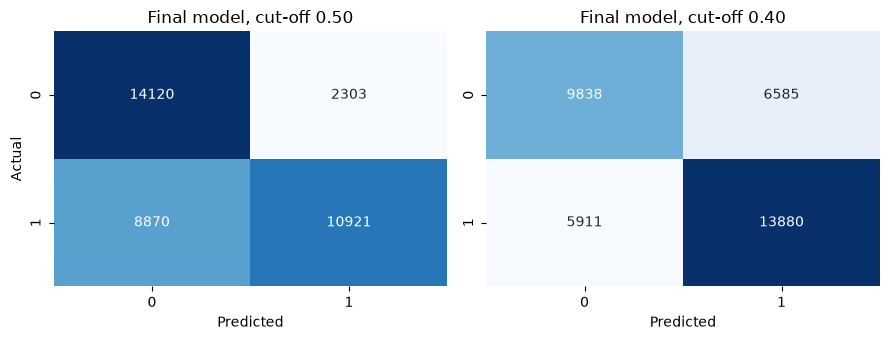

In [97]:
plt.figure(figsize=(9,3.5))

plt.subplot(1, 2, 1)
sns.heatmap(cm_final, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Final model, cut-off 0.50")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.subplot(1, 2, 2)
sns.heatmap(cm_final_040, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Final model, cut-off 0.40")
plt.xlabel("Predicted")

plt.tight_layout()
plt.show()

### Interpret the final model

- **Same performance with a simpler model.** The final model uses 20 features instead of 105 and gets AUC 0.7388 (first version 0.7391) and accuracy 0.6915 (first version 0.6917).
- **Validation and test agree** (AUC 0.7418 on validation, 0.7388 on test), so the choices made during refinement hold on unseen orders.
- **Cut-off 0.40:** recall goes from 0.5518 to 0.7013. The model catches 13,880 late orders instead of 10,921. False alarms go from 2,303 to 6,585 and precision falls to 0.6782.

### Which cut-off?

There is no correct answer without knowing the **cost of a missed late order and the cost of a false alarm**.

- If the action is cheap (an advance message to the customer, an extra check), 0.40 makes sense.
- If the action is costly (upgrading the shipment, pulling warehouse staff), 0.50 is safer.

# PART 5 — BUSINESS SOLUTION & INSIGHTS

**Business question:** What should DataCo actually do with this model?

Each finding below follows **Finding → Evidence → Interpretation → Action**.

## 5.1 Most important features in the final model

In [99]:
# feature importance from the final gradient boosting model
importance_final = pd.Series(
    gb_final.feature_importances_,
    index=top_features
).sort_values(ascending=False)

print(importance_final.round(4))

Shipping Mode_Standard Class    0.7426
Shipping Mode_Same Day          0.1288
Shipping Mode_Second Class      0.0623
Type_TRANSFER                   0.0363
Latitude                        0.0109
Longitude                       0.0073
order_day                       0.0056
order_month                     0.0015
order_year                      0.0014
Customer Segment_Corporate      0.0011
order_weekday                   0.0009
Product Price                   0.0004
Order Item Discount Rate        0.0002
Sales                           0.0002
Type_PAYMENT                    0.0001
Type_DEBIT                      0.0001
Order Item Discount             0.0001
Customer Country_Puerto Rico    0.0001
Order Item Quantity             0.0000
Customer Segment_Home Office    0.0000
dtype: float64


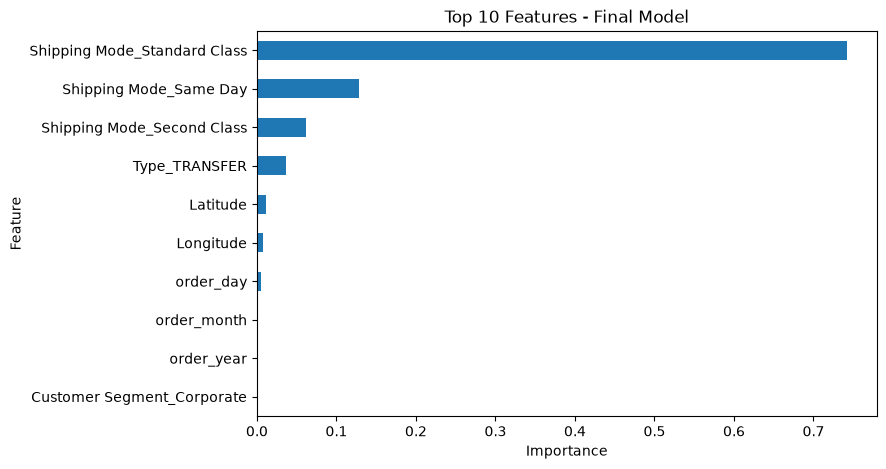

In [100]:
importance_final.head(10).sort_values().plot(kind="barh", figsize=(8,5))
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features - Final Model")
plt.show()

In [101]:
# how much of the importance comes from the shipping mode columns?
shipping_cols = ["Shipping Mode_Standard Class", "Shipping Mode_Second Class", "Shipping Mode_Same Day"]
print("Shipping mode share of importance:", round(importance_final[shipping_cols].sum() * 100, 2))

Shipping mode share of importance: 93.38


**Finding:** the prediction is driven almost entirely by shipping mode.

**Evidence:** the three shipping mode columns hold 93.38% of the importance in the final model. `Type_TRANSFER` (payment by transfer) is next with about 3.6%. `Latitude`, `Longitude` and `order_day` together are about 2.4%. Everything else is close to zero.

**Interpretation:** in 3.9 the Random Forest ranked latitude, longitude and order day high. The final model does not, which supports the caution noted there. Also, importance is not cause. A safe statement is: *shipping mode is what the model uses to separate late from on-time orders.* It does not prove that choosing First Class makes an order late. A likely reason is that the promised days for the faster modes are too tight, but this needs to be checked with the operations team.

**Action:** look at the delivery promise for each shipping mode before anything else (see 5.4).

## 5.2 How much does the model add over a simple rule?

### Predict first

Part 2 showed that First Class and Second Class orders are late most of the time. What if we skip the model and just say: *"First Class or Second Class = late, everything else = not late"*?

In [103]:
# simple rule: late if shipping mode is First Class or Second Class
# (First Class is the dropped dummy, so it is the case where the other two are both 0)
y_rule_pred = 1 - X_test_raw["Shipping Mode_Standard Class"] - X_test_raw["Shipping Mode_Same Day"]

print(metrics.confusion_matrix(y_test_raw, y_rule_pred))
print(metrics.classification_report(y_test_raw, y_rule_pred))

[[14504  1919]
 [ 9248 10543]]
              precision    recall  f1-score   support

           0       0.61      0.88      0.72     16423
           1       0.85      0.53      0.65     19791

    accuracy                           0.69     36214
   macro avg       0.73      0.71      0.69     36214
weighted avg       0.74      0.69      0.68     36214



In [104]:
results_rule = pd.DataFrame({
    'Approach': [
        'Simple shipping mode rule',
        'Final model, cut-off 0.50',
        'Final model, cut-off 0.40'
    ],
    'Accuracy': [
        metrics.accuracy_score(y_test_raw, y_rule_pred),
        metrics.accuracy_score(y_test_raw, y_final_pred),
        metrics.accuracy_score(y_test_raw, y_final_pred_040)
    ],
    'Precision': [
        metrics.precision_score(y_test_raw, y_rule_pred),
        metrics.precision_score(y_test_raw, y_final_pred),
        metrics.precision_score(y_test_raw, y_final_pred_040)
    ],
    'Recall': [
        metrics.recall_score(y_test_raw, y_rule_pred),
        metrics.recall_score(y_test_raw, y_final_pred),
        metrics.recall_score(y_test_raw, y_final_pred_040)
    ],
    'F1': [
        metrics.f1_score(y_test_raw, y_rule_pred),
        metrics.f1_score(y_test_raw, y_final_pred),
        metrics.f1_score(y_test_raw, y_final_pred_040)
    ]
})

results_rule.round(4)

,Approach,Accuracy,Precision,Recall,F1
0,Simple shipping mode rule,0.6916,0.8460,0.5327,0.6538
1,"Final model, cut-off 0.50",0.6915,0.8258,0.5518,0.6616
2,"Final model, cut-off 0.40",0.6549,0.6782,0.7013,0.6896


**Finding:** at the default cut-off, the model is hardly different from the simple rule.

**Evidence:** the rule gets accuracy 0.6916, precision 0.8460 and recall 0.5327. The final model at cut-off 0.50 gets 0.6915, 0.8258 and 0.5518.

**Interpretation:** with the information available at order time in this dataset, the model has mostly learned the shipping mode rule. What it adds is a **score** for every order. A score lets the company choose its own cut-off (at 0.40 recall rises to 0.7013) and rank orders by risk. A fixed rule cannot do that.

**Action:** present the model as a risk-scoring tool with modest accuracy. Its bigger value is that it shows clearly where the late-delivery problem sits.

## 5.3 A risk-scoring system for new orders

The model gives every order a probability of being late. We turn that into three bands that an operations team can act on:

- **Low risk** – score below 0.40
- **Medium risk** – score from 0.40 to below 0.60
- **High risk** – score 0.60 and above

In [106]:
# risk score table for the test orders
risk_table = pd.DataFrame()
risk_table["late_risk_score"] = y_final_proba
risk_table["actual_late"] = y_test_raw.values
risk_table["shipping_mode"] = df.loc[test_rows, "Shipping Mode"].values
risk_table["order_region"] = df.loc[test_rows, "Order Region"].values

risk_table["risk_band"] = pd.cut(
    risk_table["late_risk_score"],
    bins=[0, 0.40, 0.60, 1],
    labels=["Low", "Medium", "High"],
    right=False)

risk_table.head()

,late_risk_score,actual_late,shipping_mode,order_region,risk_band
0,0.376981,0,Standard Class,Oceania,Low
1,0.965519,1,First Class,Eastern Asia,High
2,0.880360,1,First Class,Eastern Asia,High
3,0.967594,1,First Class,Eastern Asia,High
4,0.967161,1,First Class,Southeast Asia,High


In [107]:
# how many orders fall in each band, and how many of them were really late?
band_summary = pd.DataFrame()
band_summary["Orders"] = risk_table["risk_band"].value_counts().sort_index()
band_summary["Share of orders %"] = round(band_summary["Orders"] / len(risk_table) * 100, 1)
band_summary["Actual late %"] = round(risk_table.groupby("risk_band", observed=True)["actual_late"].mean() * 100, 1)
band_summary

,Orders,Share of orders %,Actual late %
risk_band,,,
Low,15749,43.5,37.5
Medium,7929,21.9,41.7
High,12536,34.6,84.4


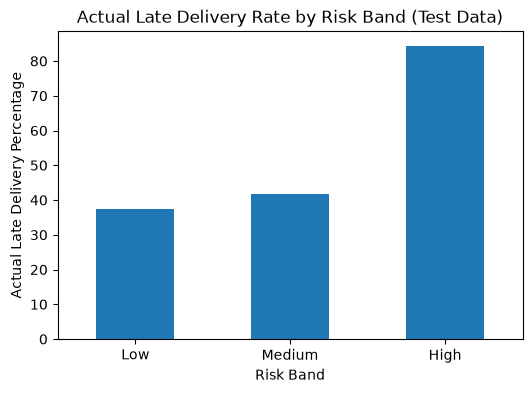

In [108]:
band_summary["Actual late %"].plot(kind="bar", figsize=(6,4))
plt.xlabel("Risk Band")
plt.ylabel("Actual Late Delivery Percentage")
plt.title("Actual Late Delivery Rate by Risk Band (Test Data)")
plt.xticks(rotation=0)
plt.show()

In [109]:
# which shipping modes sit in which band?
pd.crosstab(risk_table["shipping_mode"], risk_table["risk_band"])

risk_band,Low,Medium,High
shipping_mode,,,
First Class,0,0,5510
Same Day,453,1579,87
Second Class,0,13,6939
Standard Class,15296,6337,0


In [110]:
# average risk score vs actual late rate by shipping mode
shipping_score = pd.DataFrame()
shipping_score["Average risk score %"] = round(risk_table.groupby("shipping_mode")["late_risk_score"].mean() * 100, 1)
shipping_score["Actual late %"] = round(risk_table.groupby("shipping_mode")["actual_late"].mean() * 100, 1)
shipping_score["Orders"] = risk_table["shipping_mode"].value_counts()
shipping_score

,Average risk score %,Actual late %,Orders
shipping_mode,,,
First Class,93.9,94.9,5510
Same Day,46.7,45.3,2119
Second Class,77.2,76.4,6952
Standard Class,38.2,38.3,21633


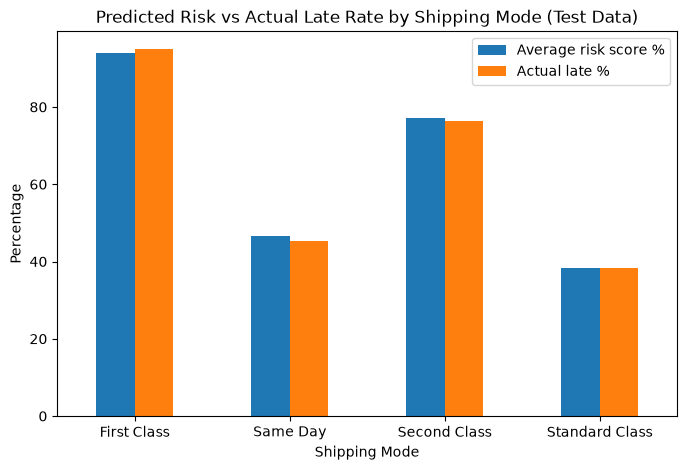

In [111]:
shipping_score[["Average risk score %", "Actual late %"]].plot(kind="bar", figsize=(8,5))
plt.xlabel("Shipping Mode")
plt.ylabel("Percentage")
plt.title("Predicted Risk vs Actual Late Rate by Shipping Mode (Test Data)")
plt.xticks(rotation=0)
plt.show()

**Finding:** the High band is a reliable warning list. The Low and Medium bands are hard to tell apart.

**Evidence:**

- **High:** 34.6% of orders, 84.4% of them were really late. This band is all First Class orders and almost all Second Class orders.
- **Medium:** 21.9% of orders, 41.7% late. **Low:** 43.5% of orders, 37.5% late.
- By shipping mode, the average predicted risk is very close to the actual late rate: First Class 93.9 vs 94.9, Second Class 77.2 vs 76.4, Same Day 46.7 vs 45.3, Standard Class 38.2 vs 38.3.

**Interpretation:** the scores can be read as realistic probabilities at shipping-mode level. Inside Standard Class the model cannot say much about *which* orders will be late. This matters because Standard Class is the biggest group: 21,633 of the 36,214 test orders, with 38.3% late. That is about 8,300 late orders, roughly 42% of all late orders in the test data.

**Action:** act on the High band now. For Standard Class, better data is needed before the model can help (see 5.6).

## 5.4 Business recommendations

| # | Recommendation | Evidence from this notebook |
|---|---|---|
| 1 | **Review the delivery promise for First Class and Second Class.** Either give a realistic number of days or add capacity for these modes. | 94.9% of First Class and 76.4% of Second Class test orders were late. Shipping mode holds 93.38% of the model's importance. |
| 2 | **Use the High risk band as an early-warning list.** Give these orders priority in the warehouse and tell the customer a realistic date in advance. | 84.4% of High band orders were really late. |
| 3 | **Do not expect the model to pick out late Standard Class orders yet.** Collect more information for them first. | Standard Class is late 38.3% of the time and holds about 42% of all late orders, but its orders fall in the Low and Medium bands, which are only 37.5% and 41.7% late. |
| 4 | **Find out why orders paid by transfer are late less often.** | `Type_TRANSFER` is the only non-shipping feature with visible importance (about 3.6%). In Part 2, transfer orders were late 48.5% of the time against about 57% for the other payment types. |
| 5 | **Do not build separate plans by customer segment, market, product category or month.** | None of these reached meaningful importance, and Part 2 showed their late rates are close to the overall average. |

Recommendation 1 does not need a model at all. When almost every order of a shipping mode is late, the promise itself is the problem.

## 5.5 How the company can use the model

### Risk-scoring at order placement

1. A new order is placed.
2. The system reads the 20 features (shipping mode, payment type, location, order date, price and discount fields).
3. The model returns a late-risk score between 0 and 1.
4. The score is converted to a band and the band decides the action.

| Risk band | Score | Suggested action |
|---|---|---|
| High | 0.60 and above | Priority picking and dispatch. Advance message to the customer with a realistic date. |
| Medium | 0.40 to below 0.60 | Watch list. Act only if the warehouse is under load that day. |
| Low | below 0.40 | Normal process. |

### Dashboard for the operations team

- Number of open orders in each risk band, updated daily
- Late rate by shipping mode and order region
- Predicted risk against actual late rate each month, to see if the model still holds
- Recall and precision of last month's alerts

The model should be retrained from time to time, especially if the delivery promises are changed after recommendation 1, because the main pattern it has learned would then change.

## 5.6 Limitations

- **Moderate performance.** Accuracy is 0.69 and AUC 0.74. At cut-off 0.50 the model misses about 45% of late orders (8,870 of 19,791). On accuracy it is no better than the simple shipping mode rule.
- **Missing information.** The data has nothing on carrier, warehouse workload, stock availability or delivery distance. These are likely reasons for delay, especially for Standard Class orders.
- **Importance is not cause.** The model shows that shipping mode separates late and on-time orders. It does not prove why.
- **Time period.** Orders run from January 2015 to January 2018. The split was by order, not by time, so the model has not been tested on a later period than it was trained on.
- **Small tuning search.** Only a few depth values were tried by hand, on one validation split. A wider search or cross-validation was not done.
- **Cut-offs chosen by judgement.** The 0.40 and 0.60 band limits are not based on real costs, because the cost of a missed late order and of a false alarm are not known.
- **Dropped detail.** City, state, country and product name columns were removed to keep the model manageable. Some local patterns may have been lost.
- **Target as given.** `Late_delivery_risk` is used as it comes in the dataset. Cancelled orders are counted as "not late", which may not be how the business wants to treat them.